# MODELO EfficientNetB0



## Configuración local

Este notebook está preparado para ejecutarse **localmente en VS Code/Jupyter**, sin Google Colab ni rutas de Kaggle.

Coloca el proyecto con esta estructura:

```text
proyecto/
├── Entrenamiento_EfficientNetB0_Retinopatia_Diabetica.ipynb
├── data/
│   ├── train_split.csv
│   ├── val_split.csv
│   └── IDRiD2/
│       └── IDRiD/
│           ├── train/images/
│           └── test/images/
└── efficientnetb0_rdr/   # se crea automáticamente
```

Descarga el dataset IDRiD2 previamente y colócalo dentro de `data/IDRiD2/`. Los archivos `train_split.csv` y `val_split.csv` también deben estar dentro de `data/`.


In [1]:
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd()

# Datos locales
DATA_DIR = PROJECT_ROOT / "data"
IDRID_DIR = DATA_DIR / "IDRiD2"

# Archivos CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# Directorios de imágenes
TRAIN_IMAGES_DIR = IDRID_DIR / "IDRiD" / "train" / "images"
TEST_IMAGES_DIR = IDRID_DIR / "IDRiD" / "test" / "images"

# Comprobar estructura
required_paths = [
    TRAIN_CSV,
    VAL_CSV,
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR
]

missing_paths = [
    path for path in required_paths
    if not path.exists()
]

if missing_paths:
    print("Faltan los siguientes archivos/directorios locales:")
    
    for path in missing_paths:
        print(f" - {path}")
    
    raise FileNotFoundError(
        "Completa la estructura local indicada antes de continuar."
    )

print("Proyecto local:", PROJECT_ROOT)
print("Dataset:", IDRID_DIR)
print("Configuración local correcta.")

Proyecto local: c:\Users\lauri\Documents\PROYECTO FINAL
Dataset: c:\Users\lauri\Documents\PROYECTO FINAL\data\IDRiD2
Configuración local correcta.


### Dependencias

Instala las dependencias **una sola vez en tu entorno virtual local**. Por ejemplo, desde la terminal de VS Code:

```bash
pip install tensorflow numpy pandas matplotlib seaborn scikit-learn plotly kaleido
```


### Dataset local

El notebook ya no descarga el dataset ni utiliza `kaggle.json`. El entrenamiento trabaja directamente con los archivos ubicados en `data/`.


# Clasificación binaria de Retinopatía Diabética con EfficientNetB0

# IMPORTACIONES Y CONFIGURACIÓN




Las librerías necesarias deben estar instaladas en el entorno virtual local antes de ejecutar el notebook.



# IMPORTACIONES Y CONFIGURACIÓN


In [ ]:


import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import gc
import json
import math
import random
import shutil
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPUS = tf.config.list_physical_devices("GPU")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if GPUS:
    mixed_precision.set_global_policy("mixed_float16")
else:
    mixed_precision.set_global_policy("float32")

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", GPUS)
print("Política de precisión:", mixed_precision.global_policy())

## Parámetros generales

In [ ]:
CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Ajuste automático según el hardware local.
BATCH_SIZE = 32 if GPUS else 8

HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 12

HEAD_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 3e-5

UNFREEZE_LAST_LAYERS = 40
DROPOUT_RATE = 0.35

# La caché guarda las imágenes redimensionadas en disco.
USE_DISK_CACHE = True

# Puede activarse si el entorno soporta XLA sin errores.
JIT_COMPILE = False

WORK_ROOT = PROJECT_ROOT

RUN_DIR = WORK_ROOT / "efficientnetb0_rdr"
CACHE_DIR = RUN_DIR / "tf_cache"
LOG_DIR = RUN_DIR / "logs"

RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

HEAD_MODEL_PATH = RUN_DIR / "efficientnetb0_head_best.keras"
FINETUNE_MODEL_PATH = RUN_DIR / "efficientnetb0_finetuned_best.keras"
FINAL_MODEL_PATH = RUN_DIR / "efficientnetb0_rdr_final.keras"

HISTORY_PATH = RUN_DIR / "historial_entrenamiento.csv"
METRICS_PATH = RUN_DIR / "metricas_validacion.json"
THRESHOLD_PATH = RUN_DIR / "umbral_clasificacion.json"
VALIDATION_PREDICTIONS_PATH = RUN_DIR / "predicciones_validacion.csv"
DASHBOARD_PATH = RUN_DIR / "dashboard_efficientnetb0.html"

print("Directorio de resultados:", RUN_DIR)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Directorio de resultados: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr
Tamaño de imagen: (224, 224)
Batch size: 8


# Limpieza del manifiesto


In [ ]:
import pandas as pd
from pathlib import Path

train_path = TRAIN_CSV
val_path = VAL_CSV

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

# ============================================================
# AUDITORÍA DEL SPLIT POR PACIENTE
# ============================================================

train_patients = set(train_df["patient_id"].astype(str))
val_patients = set(val_df["patient_id"].astype(str))

shared_patients = train_patients.intersection(val_patients)

print("===== AUDITORÍA POR PACIENTE =====")
print(f"Pacientes en TRAIN: {len(train_patients)}")
print(f"Pacientes en VALIDACIÓN: {len(val_patients)}")
print(f"Pacientes compartidos: {len(shared_patients)}")

if shared_patients:
    print("\n ERROR: Hay pacientes repartidos entre TRAIN y VALIDACIÓN.")
    print("Pacientes afectados:")
    print(sorted(shared_patients))

    raise ValueError(
        "El split no es seguro: existen pacientes "
        "presentes tanto en TRAIN como en VALIDACIÓN."
    )

else:
    print("\n CORRECTO: ningún paciente está compartido "
          "entre TRAIN y VALIDACIÓN.")

# Identificar originales: el nombre de imagen coincide con patient_id.
train_df["is_original"] = train_df["Image name"].astype(str).eq(
    train_df["patient_id"].astype(str)
)
val_df["is_original"] = val_df["Image name"].astype(str).eq(
    val_df["patient_id"].astype(str)
)

train_df["model_split"] = "train"
val_df["model_split"] = "val"

# Validación rigurosa: solo imágenes originales.
val_originals_df = val_df[val_df["is_original"]].copy()

# Manifiesto combinado recomendado para VGG16.
manifest_EfficientNetB0 = pd.concat(
    [train_df, val_originals_df],
    ignore_index=True
)

train_out = DATA_DIR / "train_split_EfficientNetB0.csv"
val_out = DATA_DIR / "val_split_EfficientNetB0.csv"
combined_out = DATA_DIR / "manifest_train_val_split_EfficientNetB0.csv"

train_df.to_csv(train_out, index=False)
val_originals_df.to_csv(val_out, index=False)
manifest_EfficientNetB0.to_csv(combined_out, index=False)

print(f"Train: {len(train_df)} filas, {train_df['patient_id'].nunique()} pacientes")
print(
    f"Validación original: {len(val_originals_df)} filas, "
    f"{val_originals_df['patient_id'].nunique()} pacientes"
)
print(f"Manifiesto combinado: {len(manifest_EfficientNetB0)} filas")

===== AUDITORÍA POR PACIENTE =====
Pacientes en TRAIN: 330
Pacientes en VALIDACIÓN: 83
Pacientes compartidos: 0

 CORRECTO: ningún paciente está compartido entre TRAIN y VALIDACIÓN.
Train: 2640 filas, 330 pacientes
Validación original: 83 filas, 83 pacientes
Manifiesto combinado: 2723 filas



# ÍNDICE ÚNICO DE IMÁGENES


In [ ]:


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
}

IMAGE_ROOTS = [
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR,
]

IMAGE_ROOTS = [
    root for root in IMAGE_ROOTS
    if root.exists()
]


def build_image_index(roots):
    """
    Recorre todos los directorios una sola vez.

    Retorna:
        {
            "idrid_001": [ruta1, ruta2],
            "idrid_001_r8": [ruta],
            ...
        }
    """
    image_index = {}
    total_images = 0

    for root in roots:
        print("Indexando:", root)

        for directory, _, filenames in os.walk(root):
            for filename in filenames:
                suffix = Path(filename).suffix.lower()

                if suffix not in IMAGE_EXTENSIONS:
                    continue

                full_path = Path(directory) / filename
                image_key = full_path.stem.lower().strip()

                image_index.setdefault(image_key, []).append(
                    str(full_path)
                )

                total_images += 1

    print("\nTotal de archivos de imagen encontrados:", total_images)
    print("Nombres únicos:", len(image_index))

    return image_index


image_index = build_image_index(IMAGE_ROOTS)

Indexando: c:\Users\lauri\Documents\PROYECTO FINAL\data\IDRiD2\IDRiD\train\images
Indexando: c:\Users\lauri\Documents\PROYECTO FINAL\data\IDRiD2\IDRiD\test\images

Total de archivos de imagen encontrados: 4128
Nombres únicos: 3304



# ASIGNAR image_path A LOS MANIFIESTOS


In [ ]:


def image_path_score(path):
    """
    Si existe el mismo nombre en Training Set y Testing Set,
    prioriza la imagen procedente del conjunto de entrenamiento.
    """
    normalized = str(path).replace("\\", "/").lower()

    score = 0

    if "/train/" in normalized:
        score += 200

    if "training set" in normalized:
        score += 200

    if "/training/" in normalized:
        score += 150

    if "/images/" in normalized:
        score += 20

    if "augmented" in normalized:
        score += 500

    if "/test/" in normalized:
        score -= 200

    if "testing set" in normalized:
        score -= 200

    return score


def resolve_image_path(image_name):
    image_key = Path(str(image_name)).stem.lower().strip()
    candidates = image_index.get(image_key, [])

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda path: (
            image_path_score(path),
            -len(path),
        ),
    )


train_df["image_path"] = train_df["Image name"].map(
    resolve_image_path
)

val_df["image_path"] = val_df["Image name"].map(
    resolve_image_path
)

missing_train = train_df[
    train_df["image_path"].isna()
]

missing_val = val_df[
    val_df["image_path"].isna()
]

print("Imágenes faltantes en entrenamiento:", len(missing_train))
print("Imágenes faltantes en validación:", len(missing_val))

if len(missing_train) > 0:
    display(missing_train[["Image name"]].head(20))

if len(missing_val) > 0:
    display(missing_val[["Image name"]].head(20))

if len(missing_train) > 0 or len(missing_val) > 0:
    raise FileNotFoundError(
        "No fue posible localizar todas las imágenes. "
        "Revisa que el dataset de ENLACE-DATA esté agregado "
        "en la sección Input del notebook."
    )

# Verificar que no se esté utilizando el mismo archivo en ambos conjuntos.
shared_paths = set(train_df["image_path"]).intersection(
    set(val_df["image_path"])
)

if shared_paths:
    raise ValueError(
        f"Hay {len(shared_paths)} archivos compartidos entre "
        "entrenamiento y validación."
    )

print("\nEjemplos de rutas resueltas:")
display(
    train_df[
        ["Image name", "binary_label", "image_path"]
    ].head(5)
)

print(train_df["image_path"].head(5))
valor = train_df["image_path"].head(20).tolist()

# Abre el archivo en modo escritura ('w')
with open("prueba.txt", "w", encoding="utf-8") as archivo:
    archivo.write("\n".join(str(path) for path in valor))


Imágenes faltantes en entrenamiento: 0
Imágenes faltantes en validación: 0

Ejemplos de rutas resueltas:


,Image name,binary_label,image_path
0,IDRiD_001,1,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
1,IDRiD_002,1,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
2,IDRiD_004,1,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
3,IDRiD_005,1,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
4,IDRiD_006,1,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...


0    c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
1    c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
2    c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
3    c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
4    c:\Users\lauri\Documents\PROYECTO FINAL\data\I...
Name: image_path, dtype: str



# COMPROBACIÓN RÁPIDA DE DECODIFICACIÓN


In [ ]:


sample_paths = pd.concat(
    [
        train_df["image_path"].sample(
            min(8, len(train_df)),
            random_state=SEED,
        ),
        val_df["image_path"].sample(
            min(4, len(val_df)),
            random_state=SEED,
        ),
    ],
    ignore_index=True,
)

decode_errors = []

for image_path in sample_paths:
    try:
        image_bytes = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False,
        )

        if image.shape[-1] != 3:
            decode_errors.append(image_path)

    except Exception as error:
        decode_errors.append(
            (image_path, str(error))
        )

if decode_errors:
    print("Archivos con problemas:")
    print(decode_errors)
else:
    print(
        f"Comprobación exitosa: "
        f"{len(sample_paths)} imágenes decodificadas."
    )

Comprobación exitosa: 12 imágenes decodificadas.



#COMPROBACIÓN RÁPIDA DE DECODIFICACIÓN




,Entrenamiento,Validación
No referible,984,248
Referible,1656,416


Pesos de clase: {0: 1.3414634146341464, 1: 0.7971014492753623}


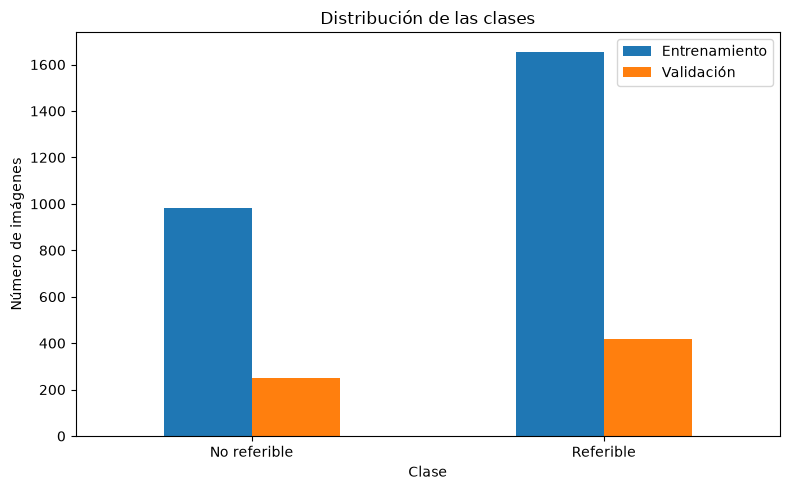

In [ ]:

train_distribution = (
    train_df["binary_label"]
    .value_counts()
    .sort_index()
)

val_distribution = (
    val_df["binary_label"]
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "Entrenamiento": train_distribution,
    "Validación": val_distribution,
}).fillna(0).astype(int)

distribution_df.index = [
    CLASS_NAMES[int(label)]
    for label in distribution_df.index
]

display(distribution_df)

classes = np.array([0, 1], dtype=np.int32)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["binary_label"].to_numpy(),
)

CLASS_WEIGHT = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Pesos de clase:", CLASS_WEIGHT)

distribution_df.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribución de las clases",
)

plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# PIPELINE

In [ ]:


AUTOTUNE = tf.data.AUTOTUNE


def dataset_fingerprint(dataframe):
    content = "\n".join(
        dataframe["image_path"].astype(str)
        + "|"
        + dataframe["binary_label"].astype(str)
    )

    return hashlib.md5(
        content.encode("utf-8")
    ).hexdigest()[:12]


def decode_and_resize(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    # Mantiene la proporción de la retina sin deformarla.
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        clip_value_min=0.0,
        clip_value_max=255.0,
    )

    # Cachear uint8 consume aproximadamente 4 veces menos espacio.
    image = tf.cast(image, tf.uint8)
    label = tf.cast(label, tf.float32)

    return image, label


def make_dataset(
    dataframe,
    training=False,
    cache_name=None,
):
    paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["binary_label"].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        decode_and_resize,
        num_parallel_calls=AUTOTUNE,
        deterministic=not training,
    )

    if USE_DISK_CACHE and cache_name is not None:
        fingerprint = dataset_fingerprint(dataframe)

        cache_path = CACHE_DIR / (
            f"{cache_name}_{fingerprint}_"
            f"{IMG_HEIGHT}x{IMG_WIDTH}"
        )

        dataset = dataset.cache(str(cache_path))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = make_dataset(
    train_df,
    training=True,
    cache_name="train",
)

val_ds = make_dataset(
    val_df,
    training=False,
    cache_name="val",
)

print("Pipeline de entrenamiento:", train_ds)
print("Pipeline de validación:", val_ds)

Pipeline de entrenamiento: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>
Pipeline de validación: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>



# REVISIÓN UN SOLO LOTE


Forma de las imágenes: (8, 224, 224, 3)
Tipo de dato: <dtype: 'uint8'>
Forma de etiquetas: (8,)
Rango: 0 254


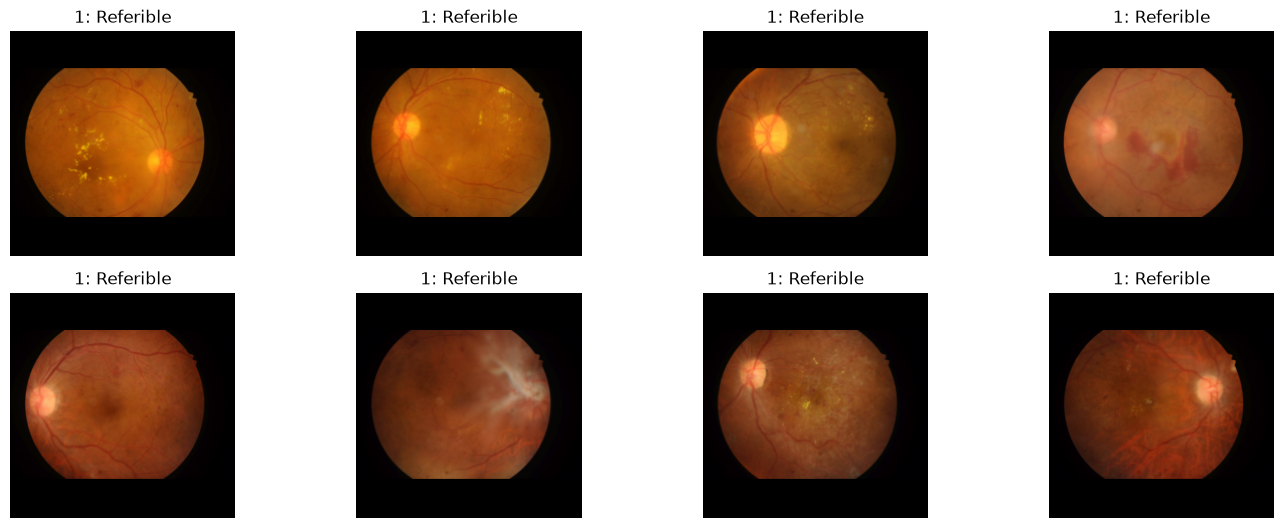

In [ ]:
# Creamos un minidataset temporal sin caché ni mezcla para que la revisión sea instantánea
quick_check_ds = make_dataset(
    train_df.head(BATCH_SIZE),
    training=False,
    cache_name=None,
)

batch_images, batch_labels = next(
    iter(quick_check_ds.take(1))
)

print("Forma de las imágenes:", batch_images.shape)
print("Tipo de dato:", batch_images.dtype)
print("Forma de etiquetas:", batch_labels.shape)
print("Rango:", batch_images.numpy().min(), batch_images.numpy().max())

plt.figure(figsize=(14, 8))

images_to_show = min(12, len(batch_images))

for index in range(images_to_show):
    plt.subplot(3, 4, index + 1)

    plt.imshow(
        batch_images[index].numpy().astype(np.uint8)
    )

    label = int(batch_labels[index].numpy())

    plt.title(
        f"{label}: {CLASS_NAMES[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# MODELO EFFICIENTNETB0


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_HEIGHT = 224
IMG_WIDTH = 224
DROPOUT_RATE = 0.35
SEED = 42


data_augmentation = keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal",
            seed=SEED,
        ),
        layers.RandomRotation(
            factor=0.025,
            fill_mode="reflect",
            seed=SEED,
        ),
        layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=(-0.05, 0.05),
            fill_mode="reflect",
            seed=SEED,
        ),
        layers.RandomContrast(
            factor=0.10,
            seed=SEED,
        ),
    ],
    name="data_augmentation",
)

# Keras descargará automáticamente los pesos de ImageNet
backbone = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    pooling=None,
)

backbone.trainable = False

inputs = keras.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    dtype=tf.uint8,
    name="image",
)

# Convierte uint8 a punto flotante conservando el rango 0-255.
x = layers.Rescaling(
    scale=1.0,
    name="cast_to_float",
)(inputs)

x = data_augmentation(x)

# training=False mantiene BatchNormalization estable.
x = backbone(
    x,
    training=False,
)

x = layers.GlobalAveragePooling2D(
    name="gap",
)(x)

x = layers.Dropout(
    DROPOUT_RATE,
    name="head_dropout",
)(x)

# --- Capas intermedias originales ---
x = layers.Dense(
    256,
    activation="swish",
    kernel_regularizer=keras.regularizers.l2(1e-4)
)(x)
x = layers.Dropout(0.2)(x)

x = layers.Dense(
    128,
    activation="swish",
    kernel_regularizer=keras.regularizers.l2(1e-4)
)(x)
x = layers.Dropout(0.2)(x)

x = layers.Dense(
    64,
    activation="swish",
    kernel_regularizer=keras.regularizers.l2(1e-4)
)(x)
x = layers.Dropout(0.2)(x)
# ----------------------------------


outputs = layers.Dense(
    units=1,
    activation="sigmoid",
    kernel_regularizer=keras.regularizers.l2(1e-4),
    dtype="float32",
    name="prediction",
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_RDR",
)

def create_optimizer(learning_rate):
    try:
        return keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=1e-5,
            clipnorm=1.0,
        )
    except (AttributeError, TypeError):
        return keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0,
        )


def get_metrics():
    return [
        keras.metrics.BinaryAccuracy(
            name="accuracy",
            threshold=0.5,
        ), 
        keras.metrics.AUC(
            name="auc_roc",
            curve="ROC",
        ),
        keras.metrics.AUC(
            name="auc_pr",
            curve="PR",
        ),
        keras.metrics.Precision(
            name="precision",
            thresholds=0.5,
        ),
        keras.metrics.Recall(
            name="recall",
            thresholds=0.5,
        ),
    ]


def compile_model(model_to_compile, learning_rate):
    compile_arguments = dict(
        optimizer=create_optimizer(learning_rate),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=get_metrics(),
        steps_per_execution=10,
    )

    if JIT_COMPILE:
        compile_arguments["jit_compile"] = True

    model_to_compile.compile(**compile_arguments)


compile_model(
    model,
    learning_rate=HEAD_LEARNING_RATE,
)


# Crear un nuevo modelo omitiendo las primeras N capas de aumentación
model_limpio = tf.keras.Sequential(model.layers[3:]) 

model_limpio.summary()


print(
    "Parámetros entrenables:",
    sum(tf.size(w).numpy() for w in model.trainable_weights)
)

print(
    "Parámetros no entrenables:",
    sum(tf.size(w).numpy() for w in model.non_trainable_weights)
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,418,724 (16.86 MB)

 Trainable params: 369,153 (1.41 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Parámetros entrenables: 369153
Parámetros no entrenables: 4049571


In [ ]:
print("Nombre del backbone:", backbone.name)
print("Backbone entrenable:", backbone.trainable)
print("Cantidad de pesos:", len(backbone.weights))
print("Cantidad de parámetros:", backbone.count_params())

Nombre del backbone: efficientnetb0
Backbone entrenable: False
Cantidad de pesos: 312
Cantidad de parámetros: 4049571


In [ ]:
if 'model' in locals():
    print("Capas en el modelo principal:", len(model.layers))
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            print(f"Capas dentro del submodelo '{layer.name}':", len(layer.layers))
else:
    print("El modelo no está definido. Por favor, ejecuta las celdas anteriores primero.")

Capas en el modelo principal: 13
Capas dentro del submodelo 'data_augmentation': 4
Capas dentro del submodelo 'efficientnetb0': 238


#Callbacks

In [ ]:

def create_callbacks(
    phase_name,
    checkpoint_path,
    patience=4,
):
    phase_log_path = LOG_DIR / (
        f"{phase_name}_training_log.csv"
    )

    backup_path = RUN_DIR / (
        f"backup_{phase_name}"
    )

    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_auc_pr",
            mode="max",
            save_best_only=True,
            save_weights_only=False,
            verbose=1,
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_auc_pr",
            mode="max",
            patience=patience,
            restore_best_weights=True,
            verbose=1,
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1,
        ),

        keras.callbacks.CSVLogger(
            filename=str(phase_log_path),
            append=False,
        ),

        keras.callbacks.BackupAndRestore(
            backup_dir=str(backup_path),
        ),

        keras.callbacks.TerminateOnNaN(),
    ]


# ENTRENAMIENTO DE LA CABEZA


In [ ]:


head_callbacks = create_callbacks(
    phase_name="head",
    checkpoint_path=HEAD_MODEL_PATH,
    patience=3,
)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=CLASS_WEIGHT,
    callbacks=head_callbacks,
    verbose=1,
)

print("Mejor modelo de la fase 1:")
print(HEAD_MODEL_PATH)

Epoch 1/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.8098 - auc_pr: 0.9394 - auc_roc: 0.8957 - loss: 0.4800 - precision: 0.8811 - recall: 0.8056
Epoch 1: val_auc_pr improved from None to 0.99067, saving model to c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_head_best.keras

Epoch 1: finished saving model to c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_head_best.keras
330/330 ━━━━━━━━━━━━━━━━━━━━ 79s 238ms/step - accuracy: 0.8098 - auc_pr: 0.9394 - auc_roc: 0.8957 - loss: 0.4800 - precision: 0.8811 - recall: 0.8056 - val_accuracy: 0.8976 - val_auc_pr: 0.9907 - val_auc_roc: 0.9827 - val_loss: 0.3222 - val_precision: 1.0000 - val_recall: 0.8365 - learning_rate: 0.0010
Epoch 2/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8360 - auc_pr: 0.9569 - auc_roc: 0.9246 - loss: 0.4134 - precision: 0.9079 - recall: 0.8219
Epoch 2: val_auc_pr improved from 0.99067 to 0.99238, saving model to c:\Users\lauri\Documents\P


# FINE-TUNING


In [ ]:


# Partimos del mejor modelo de la primera fase.
model = keras.models.load_model(
    HEAD_MODEL_PATH
)

backbone = model.get_layer(
    "efficientnetb0"
)

backbone.trainable = True

# Congelar todas las capas excepto las últimas.
for layer in backbone.layers[:-UNFREEZE_LAST_LAYERS]:
    layer.trainable = False

# Mantener BatchNormalization congelada durante fine-tuning.
for layer in backbone.layers[-UNFREEZE_LAST_LAYERS:]:
    if isinstance(
        layer,
        keras.layers.BatchNormalization,
    ):
        layer.trainable = False

trainable_backbone_layers = sum(
    int(layer.trainable)
    for layer in backbone.layers
)

print(
    "Capas entrenables del backbone:",
    trainable_backbone_layers,
)

compile_model(
    model,
    learning_rate=FINE_TUNE_LEARNING_RATE,
)

finetune_callbacks = create_callbacks(
    phase_name="finetune",
    checkpoint_path=FINETUNE_MODEL_PATH,
    patience=4,
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=CLASS_WEIGHT,
    callbacks=finetune_callbacks,
    verbose=1,
)

Capas entrenables del backbone: 32
Epoch 1/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.8837 - auc_pr: 0.9790 - auc_roc: 0.9622 - loss: 0.3063 - precision: 0.9394 - recall: 0.8708
Epoch 1: val_auc_pr improved from None to 0.99249, saving model to c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_finetuned_best.keras
330/330 ━━━━━━━━━━━━━━━━━━━━ 104s 314ms/step - accuracy: 0.8837 - auc_pr: 0.9790 - auc_roc: 0.9622 - loss: 0.3063 - precision: 0.9394 - recall: 0.8708 - val_accuracy: 0.9458 - val_auc_pr: 0.9925 - val_auc_roc: 0.9864 - val_loss: 0.2093 - val_precision: 0.9567 - val_recall: 0.9567 - learning_rate: 3.0000e-05
Epoch 2/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.9110 - auc_pr: 0.9835 - auc_roc: 0.9712 - loss: 0.2782 - precision: 0.9494 - recall: 0.9064
Epoch 2: val_auc_pr improved from 0.99249 to

# COMPARAR FASE 1 VS FINE-TUNING

In [ ]:
#

candidate_paths = [
    HEAD_MODEL_PATH,
    FINETUNE_MODEL_PATH,
]

comparison_results = []

for candidate_path in candidate_paths:
    candidate_model = keras.models.load_model(
        candidate_path
    )

    candidate_metrics = candidate_model.evaluate(
        val_ds,
        return_dict=True,
        verbose=0,
    )

    comparison_results.append({
        "model_path": str(candidate_path),
        **{
            metric_name: float(metric_value)
            for metric_name, metric_value
            in candidate_metrics.items()
        },
    })

    del candidate_model
    gc.collect()

comparison_df = pd.DataFrame(
    comparison_results
)

display(
    comparison_df.sort_values(
        "auc_pr",
        ascending=False,
    )
)

best_row = comparison_df.sort_values(
    "auc_pr",
    ascending=False,
).iloc[0]

BEST_CANDIDATE_PATH = Path(
    best_row["model_path"]
)

model = keras.models.load_model(
    BEST_CANDIDATE_PATH
)

model.save(
    FINAL_MODEL_PATH,
    overwrite=True,
)

print("Mejor candidato:", BEST_CANDIDATE_PATH)
print("Modelo final guardado en:", FINAL_MODEL_PATH)

,model_path,accuracy,auc_pr,auc_roc,loss,precision,recall
1,c:\Users\lauri\Documents\PROYECTO FINAL\effici...,0.942771,0.995460,0.991756,0.200057,0.933486,0.978365
0,c:\Users\lauri\Documents\PROYECTO FINAL\effici...,0.929217,0.993651,0.988359,0.227041,0.984252,0.901442


Mejor candidato: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_finetuned_best.keras
Modelo final guardado en: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_rdr_final.keras



# HISTORIAL DE ENTRENAMIENTO


,epoch,accuracy,auc_pr,auc_roc,loss,precision,recall,val_accuracy,val_auc_pr,val_auc_roc,val_loss,val_precision,val_recall,learning_rate,phase
14,15,0.959848,0.995043,0.991846,0.170535,0.972561,0.963164,0.942771,0.995460,0.991756,0.200057,0.933486,0.978365,2.700000e-06,Fine-tuning
15,16,0.963258,0.994770,0.992069,0.164737,0.977928,0.963164,0.938253,0.995009,0.990850,0.187304,0.947494,0.954327,2.700000e-06,Fine-tuning
16,17,0.962500,0.994990,0.992474,0.164663,0.974406,0.965580,0.935241,0.995066,0.990981,0.192943,0.936768,0.961538,2.700000e-06,Fine-tuning
17,18,0.964394,0.995574,0.993665,0.153537,0.980911,0.961957,0.939759,0.994433,0.989478,0.193957,0.949761,0.954327,2.700000e-06,Fine-tuning
18,19,0.962879,0.996699,0.994081,0.154150,0.978501,0.961957,0.936747,0.994613,0.989837,0.197858,0.938967,0.961538,8.100000e-07,Fine-tuning


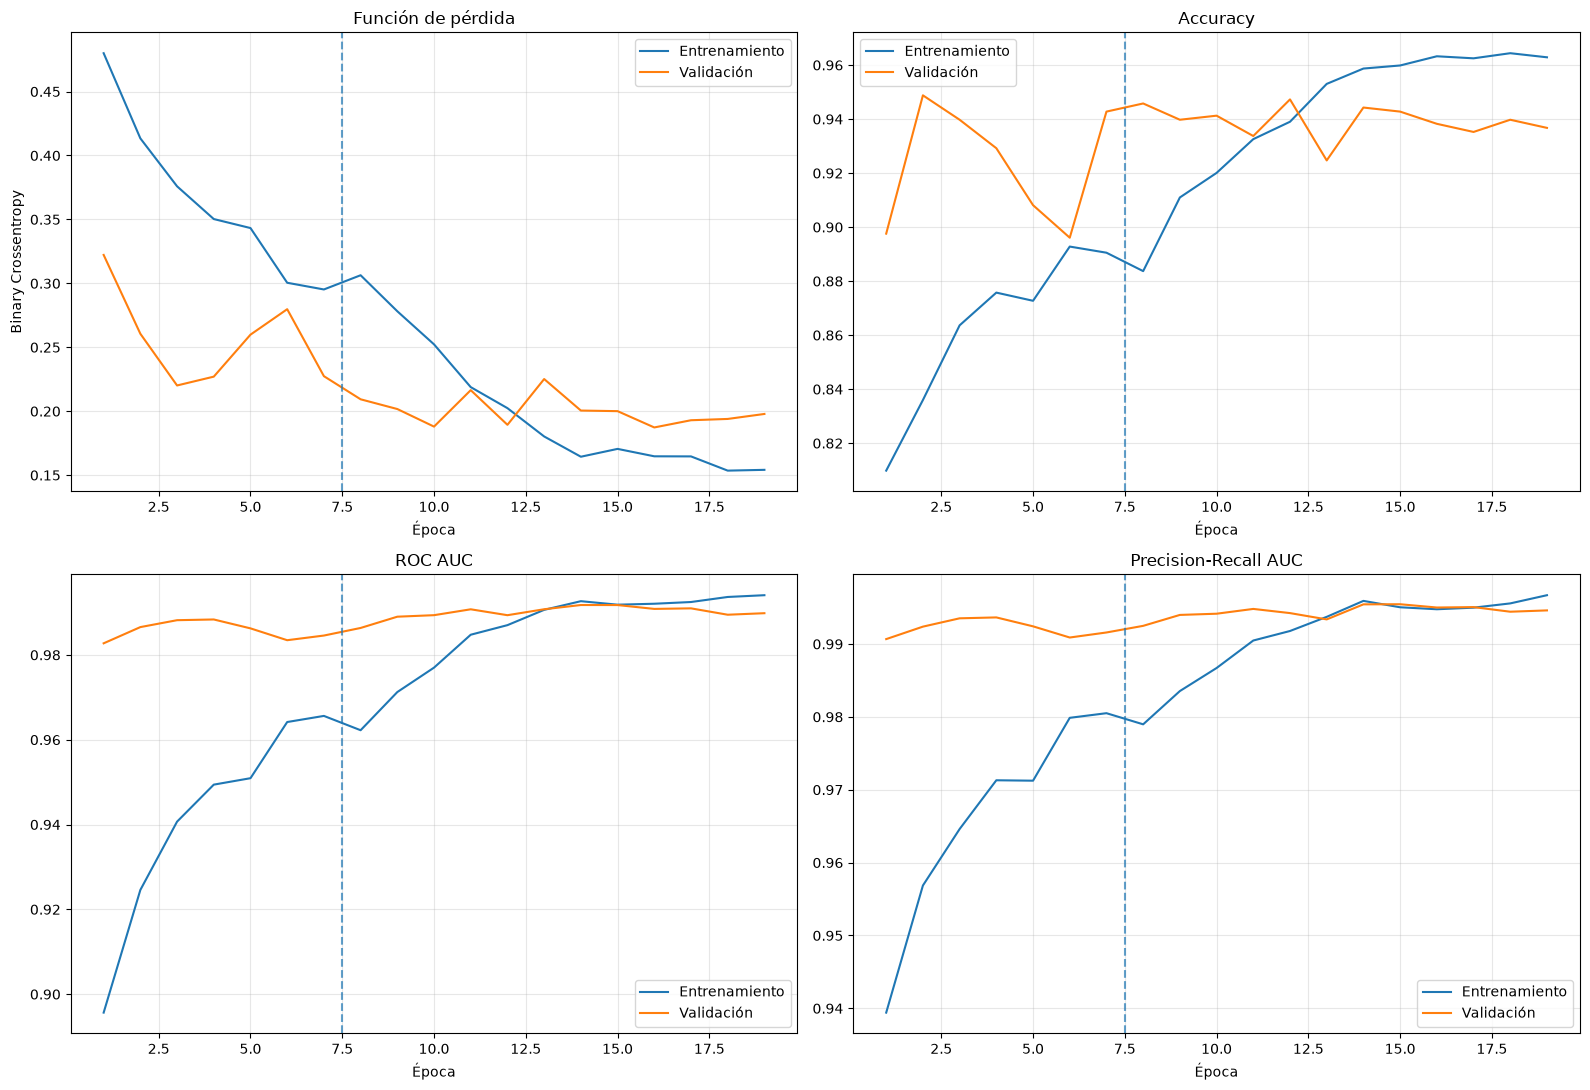

In [ ]:


head_history_df = pd.DataFrame(
    history_head.history
)

head_history_df["phase"] = "Cabeza"

finetune_history_df = pd.DataFrame(
    history_finetune.history
)

finetune_history_df["phase"] = "Fine-tuning"

history_df = pd.concat(
    [
        head_history_df,
        finetune_history_df,
    ],
    ignore_index=True,
)

history_df.insert(
    0,
    "epoch",
    np.arange(1, len(history_df) + 1),
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

display(history_df.tail())

phase_boundary = len(head_history_df)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11),
)

# Pérdida
axes[0, 0].plot(
    history_df["epoch"],
    history_df["loss"],
    label="Entrenamiento",
)

axes[0, 0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validación",
)

axes[0, 0].set_title("Función de pérdida")
axes[0, 0].set_xlabel("Época")
axes[0, 0].set_ylabel("Binary Crossentropy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Accuracy
axes[0, 1].plot(
    history_df["epoch"],
    history_df["accuracy"],
    label="Entrenamiento",
)

axes[0, 1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validación",
)

axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Época")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# ROC AUC
axes[1, 0].plot(
    history_df["epoch"],
    history_df["auc_roc"],
    label="Entrenamiento",
)

axes[1, 0].plot(
    history_df["epoch"],
    history_df["val_auc_roc"],
    label="Validación",
)

axes[1, 0].set_title("ROC AUC")
axes[1, 0].set_xlabel("Época")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# PR AUC
axes[1, 1].plot(
    history_df["epoch"],
    history_df["auc_pr"],
    label="Entrenamiento",
)

axes[1, 1].plot(
    history_df["epoch"],
    history_df["val_auc_pr"],
    label="Validación",
)

axes[1, 1].set_title("Precision-Recall AUC")
axes[1, 1].set_xlabel("Época")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

for axis in axes.flat:
    axis.axvline(
        phase_boundary + 0.5,
        linestyle="--",
        alpha=0.7,
        label="Inicio fine-tuning",
    )

plt.tight_layout()
plt.show()

#PREDICCIONES DE VALIDACIÓN Y UMBRAL

In [ ]:
# ============================================================
# CELDA 17: PREDICCIONES DE VALIDACIÓN Y UMBRAL
# ============================================================

model = keras.models.load_model(
    FINAL_MODEL_PATH
)

y_true = (
    val_df["binary_label"]
    .astype(int)
    .to_numpy()
)

y_probability = (
    model.predict(
        val_ds,
        verbose=1,
    )
    .reshape(-1)
)

if len(y_probability) != len(y_true):
    raise ValueError(
        "La cantidad de predicciones no coincide con "
        "el número de filas de validación."
    )

# ------------------------------------------------------------
# Umbral que maximiza F1
# ------------------------------------------------------------

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_true,
        y_probability,
    )
)

if len(pr_thresholds) > 0:
    f1_values = (
        2
        * precision_values[:-1]
        * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 1e-8
        )
    )

    best_f1_index = int(
        np.nanargmax(f1_values)
    )

    THRESHOLD_F1 = float(
        pr_thresholds[best_f1_index]
    )
else:
    THRESHOLD_F1 = 0.5

# ------------------------------------------------------------
# Umbral alternativo para sensibilidad mínima de 90 %
# ------------------------------------------------------------

TARGET_SENSITIVITY = 0.90

fpr_values, tpr_values, roc_thresholds = roc_curve(
    y_true,
    y_probability,
)

valid_indices = np.where(
    tpr_values >= TARGET_SENSITIVITY
)[0]

if len(valid_indices) > 0:
    best_sensitivity_index = valid_indices[
        np.argmin(fpr_values[valid_indices])
    ]

    THRESHOLD_SENSITIVITY = float(
        np.clip(
            roc_thresholds[best_sensitivity_index],
            0.0,
            1.0,
        )
    )
else:
    THRESHOLD_SENSITIVITY = 0.5

# Umbral usado por defecto para la clasificación.
SELECTED_THRESHOLD = THRESHOLD_F1

print("Umbral estándar:", 0.5)
print("Umbral con mejor F1:", round(THRESHOLD_F1, 4))
print(
    "Umbral para sensibilidad >= 90 %:",
    round(THRESHOLD_SENSITIVITY, 4),
)
print(
    "Umbral seleccionado:",
    round(SELECTED_THRESHOLD, 4),
)

83/83 ━━━━━━━━━━━━━━━━━━━━ 30s 358ms/step 
Umbral estándar: 0.5
Umbral con mejor F1: 0.8753
Umbral para sensibilidad >= 90 %: 0.9823
Umbral seleccionado: 0.8753



# MÉTRICAS BINARIAS



In [ ]:


def calculate_binary_metrics(
    true_labels,
    probabilities,
    threshold,
):
    predicted_labels = (
        probabilities >= threshold
    ).astype(int)

    matrix = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1],
    )

    tn, fp, fn, tp = matrix.ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    negative_predictive_value = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),
        "accuracy": float(
            accuracy_score(
                true_labels,
                predicted_labels,
            )
        ),
        "precision": float(
            precision_score(
                true_labels,
                predicted_labels,
                zero_division=0,
            )
        ),
        "sensitivity_recall": float(sensitivity),
        "specificity": float(specificity),
        "f1_score": float(
            f1_score(
                true_labels,
                predicted_labels,
                zero_division=0,
            )
        ),
        "npv": float(negative_predictive_value),
        "roc_auc": float(
            roc_auc_score(
                true_labels,
                probabilities,
            )
        ),
        "pr_auc": float(
            average_precision_score(
                true_labels,
                probabilities,
            )
        ),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


metrics_threshold_05 = calculate_binary_metrics(
    y_true,
    y_probability,
    threshold=0.5,
)

metrics_selected = calculate_binary_metrics(
    y_true,
    y_probability,
    threshold=SELECTED_THRESHOLD,
)

metrics_sensitivity = calculate_binary_metrics(
    y_true,
    y_probability,
    threshold=THRESHOLD_SENSITIVITY,
)

metrics_comparison = pd.DataFrame(
    [
        {
            "Configuración": "Umbral 0.50",
            **metrics_threshold_05,
        },
        {
            "Configuración": "Mejor F1",
            **metrics_selected,
        },
        {
            "Configuración": "Sensibilidad >= 90 %",
            **metrics_sensitivity,
        },
    ]
)

display(
    metrics_comparison[
        [
            "Configuración",
            "threshold",
            "accuracy",
            "precision",
            "sensitivity_recall",
            "specificity",
            "f1_score",
            "roc_auc",
            "pr_auc",
        ]
    ]
)

y_pred_selected = (
    y_probability >= SELECTED_THRESHOLD
).astype(int)

print(
    classification_report(
        y_true,
        y_pred_selected,
        labels=[0, 1],
        target_names=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        digits=4,
        zero_division=0,
    )
)

,Configuración,threshold,accuracy,precision,sensitivity_recall,specificity,f1_score,roc_auc,pr_auc
0,Umbral 0.50,0.500000,0.942771,0.933486,0.978365,0.883065,0.955399,0.991916,0.995551
1,Mejor F1,0.875314,0.954819,0.977723,0.949519,0.963710,0.963415,0.991916,0.995551
2,Sensibilidad >= 90 %,0.982325,0.948795,0.994819,0.923077,0.991935,0.957606,0.991916,0.995551


              precision    recall  f1-score   support

No referible     0.9192    0.9637    0.9409       248
   Referible     0.9777    0.9495    0.9634       416

    accuracy                         0.9548       664
   macro avg     0.9485    0.9566    0.9522       664
weighted avg     0.9559    0.9548    0.9550       664




# GRÁFICAS DE EVALUACIÓN


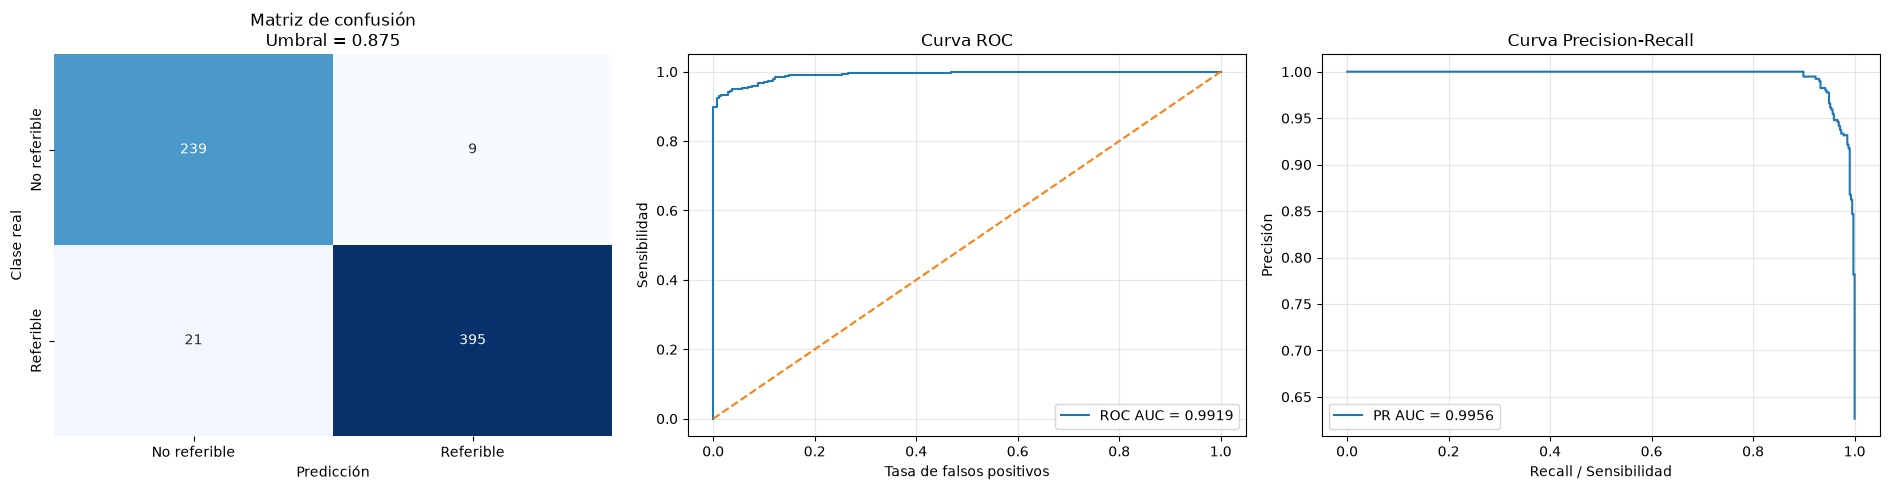

In [ ]:


cm_selected = confusion_matrix(
    y_true,
    y_pred_selected,
    labels=[0, 1],
)

fpr_curve, tpr_curve, _ = roc_curve(
    y_true,
    y_probability,
)

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_true,
        y_probability,
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5),
)

sns.heatmap(
    cm_selected,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        CLASS_NAMES[0],
        CLASS_NAMES[1],
    ],
    yticklabels=[
        CLASS_NAMES[0],
        CLASS_NAMES[1],
    ],
    ax=axes[0],
)

axes[0].set_title(
    f"Matriz de confusión\n"
    f"Umbral = {SELECTED_THRESHOLD:.3f}"
)

axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].plot(
    fpr_curve,
    tpr_curve,
    label=(
        f"ROC AUC = "
        f"{metrics_selected['roc_auc']:.4f}"
    ),
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Sensibilidad")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    recall_curve,
    precision_curve,
    label=(
        f"PR AUC = "
        f"{metrics_selected['pr_auc']:.4f}"
    ),
)

axes[2].set_title("Curva Precision-Recall")
axes[2].set_xlabel("Recall / Sensibilidad")
axes[2].set_ylabel("Precisión")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# GUARDAR RESULTADOS



In [ ]:

validation_predictions_df = val_df[
    [
        "Image name",
        "patient_id",
        "binary_label",
        "image_path",
    ]
].copy()

validation_predictions_df[
    "probability_referable"
] = y_probability

validation_predictions_df[
    "predicted_label"
] = y_pred_selected

validation_predictions_df[
    "predicted_class"
] = validation_predictions_df[
    "predicted_label"
].map(CLASS_NAMES)

validation_predictions_df[
    "correct_prediction"
] = (
    validation_predictions_df["binary_label"]
    == validation_predictions_df["predicted_label"]
)

validation_predictions_df.to_csv(
    VALIDATION_PREDICTIONS_PATH,
    index=False,
)

metrics_payload = {
    "class_names": CLASS_NAMES,
    "selected_threshold": float(
        SELECTED_THRESHOLD
    ),
    "threshold_f1": float(
        THRESHOLD_F1
    ),
    "threshold_sensitivity_90": float(
        THRESHOLD_SENSITIVITY
    ),
    "metrics_threshold_0_5": metrics_threshold_05,
    "metrics_selected_threshold": metrics_selected,
    "metrics_sensitivity_90": metrics_sensitivity,
    "best_candidate_model": str(
        BEST_CANDIDATE_PATH
    ),
    "final_model": str(
        FINAL_MODEL_PATH
    ),
}

with open(
    METRICS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metrics_payload,
        file,
        indent=4,
        ensure_ascii=False,
    )

with open(
    THRESHOLD_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "threshold": float(
                SELECTED_THRESHOLD
            ),
            "class_0": CLASS_NAMES[0],
            "class_1": CLASS_NAMES[1],
        },
        file,
        indent=4,
        ensure_ascii=False,
    )

print("Predicciones:", VALIDATION_PREDICTIONS_PATH)
print("Métricas:", METRICS_PATH)
print("Umbral:", THRESHOLD_PATH)

Predicciones: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\predicciones_validacion.csv
Métricas: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\metricas_validacion.json
Umbral: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\umbral_clasificacion.json


In [ ]:
# Los resultados ya se guardan directamente en el disco local.
print("Modelo final:", FINAL_MODEL_PATH)
print("Directorio de resultados:", RUN_DIR)
print("No es necesario descargar archivos: están disponibles localmente.")


Modelo final: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_rdr_final.keras
Directorio de resultados: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr
No es necesario descargar archivos: están disponibles localmente.



#  CARGAR MODELO ENTRENADO


### Extraer archivo ZIP y Cargar Modelo

### Carga del modelo local

No es necesario comprimir, descargar ni descomprimir el modelo. Se carga directamente desde `efficientnetb0_rdr/`.


In [ ]:
import tensorflow as tf
from tensorflow import keras
import json
from pathlib import Path
import numpy as np

LOADED_MODEL_PATH = RUN_DIR / "efficientnetb0_rdr_final.keras"

LOADED_THRESHOLD_PATH = RUN_DIR / "umbral_clasificacion.json"

if not LOADED_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"No existe el modelo: {LOADED_MODEL_PATH}"
    )

loaded_model = keras.models.load_model(
    LOADED_MODEL_PATH
)

with open(
    LOADED_THRESHOLD_PATH,
    "r",
    encoding="utf-8",
) as file:
    threshold_config = json.load(file)

LOADED_THRESHOLD = float(
    threshold_config["threshold"]
)

print("Modelo cargado:", LOADED_MODEL_PATH)
print("Umbral cargado:", LOADED_THRESHOLD)

Modelo cargado: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\efficientnetb0_rdr_final.keras
Umbral cargado: 0.8753141760826111


#Predicciones de imagenes Externas

In [ ]:
import pandas as pd


# CAMBIAR ESTA RUTA por la carpeta que contiene
# las imágenes que quieres clasificar.
PREDICT_DIR = TEST_IMAGES_DIR

# hacer una dataframe de val_split.csv
df_val_split = pd.read_csv(DATA_DIR / "val_split_EfficientNetB0.csv")

df_val_split.head(5)

,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split
0,IDRiD_003,2,2,Clinically_Significant_Macular_Edema,Advanced nonproliferative diabetic changes wit...,1,IDRiD_003,True,val
1,IDRiD_012,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_012,True,val
2,IDRiD_028,4,2,Severe_PDR,Advanced proliferative diabetic retinopathy wi...,1,IDRiD_028,True,val
3,IDRiD_029,2,2,Clinically_Significant_Macular_Edema,Moderate nonproliferative diabetic retinopathy...,1,IDRiD_029,True,val
4,IDRiD_031,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_031,True,val


In [ ]:
# unir la columna "Image name" con PREDICT_DIR
df_val_split["image_path"] = PREDICT_DIR / df_val_split["Image name"]

print(df_val_split.head(2))

#Seleccionar aleatoriamente 10 candidatos
df_val_split = df_val_split.sample(n=20)


#hacer una prediccion por cada uno de esos candidatos  y plotearlo



  Image name  Retinopathy grade  Risk of macular edema  \
0  IDRiD_003                  2                      2   
1  IDRiD_012                  3                      2   

                                  class  \
0  Clinically_Significant_Macular_Edema   
1  Clinically_Significant_Macular_Edema   

                                            Captions  binary_label patient_id  \
0  Advanced nonproliferative diabetic changes wit...             1  IDRiD_003   
1  Severe diabetic retinopathy with extensive ret...             1  IDRiD_012   

   is_original model_split                                         image_path  
0         True         val  c:\Users\lauri\Documents\PROYECTO FINAL\data\I...  
1         True         val  c:\Users\lauri\Documents\PROYECTO FINAL\data\I...  


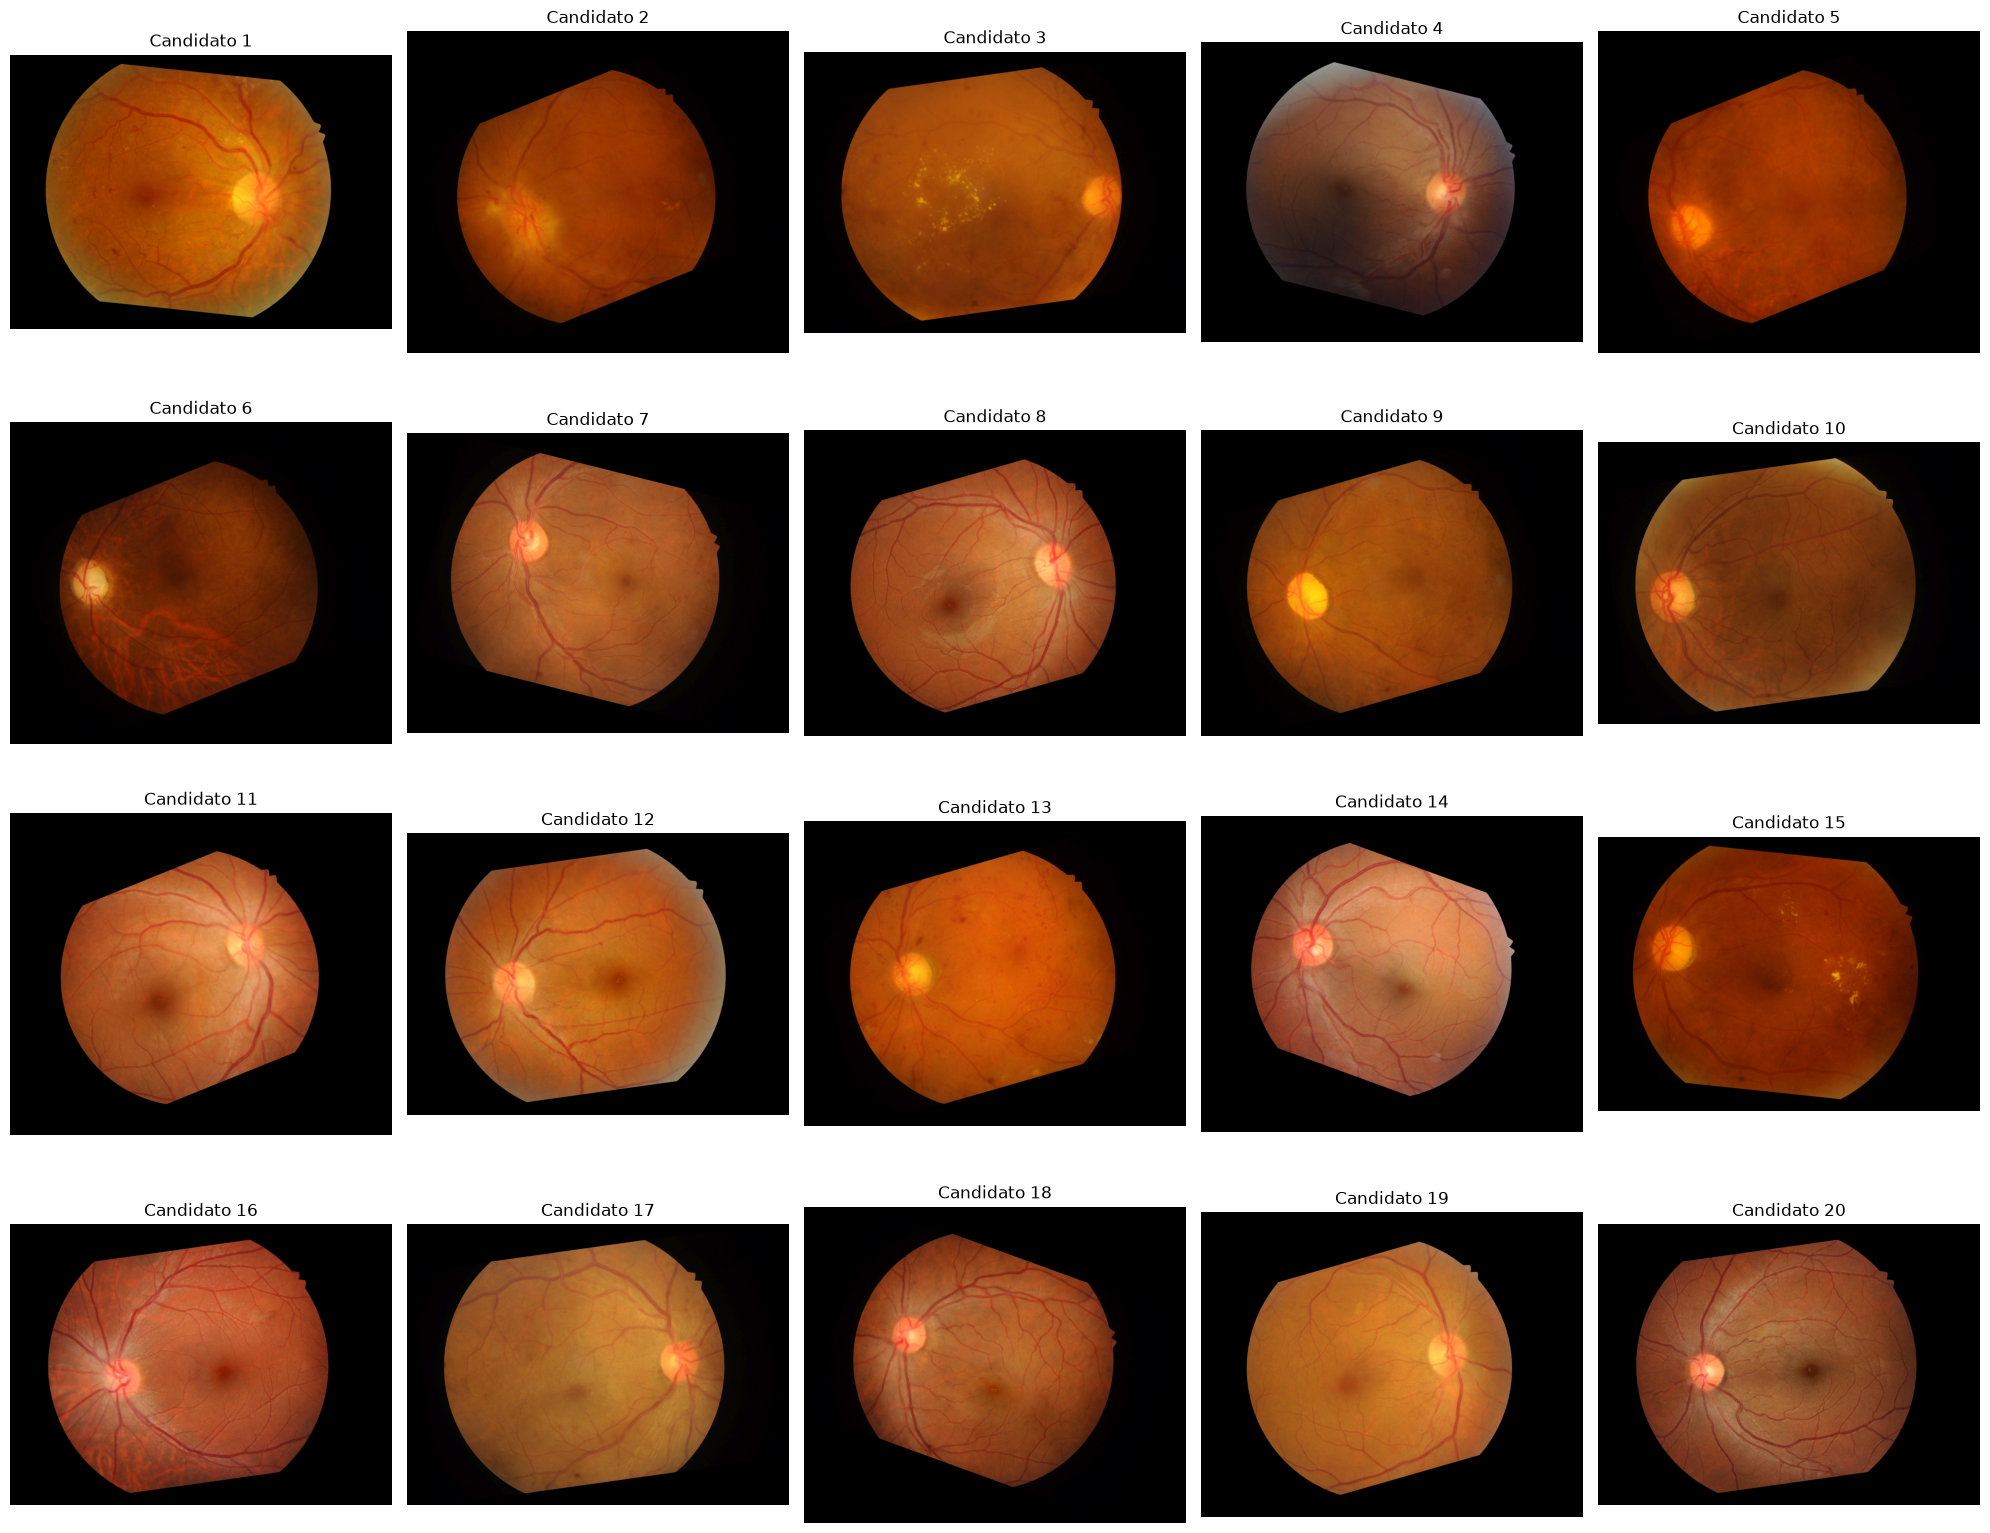

In [ ]:
import matplotlib.pyplot as plt
import random
import math

lista_de_Prueba = []
# Configuramos la cuadrícula
n_images = len(df_val_split)
cols = 5
rows = math.ceil(n_images / cols)
plt.figure(figsize=(20, 4 * rows))

nombre_Imagenes = df_val_split['Image name'].tolist()

variaciones = ["", "_L14", "_L20", "_L6", "_R16", "_R22", "_R8", "_VFLIP"]

for i, ruta in enumerate(df_val_split['image_path']):
    numero_aleatorio = random.randint(0, len(variaciones) - 1)


    cadena = str(ruta) + variaciones[numero_aleatorio] + ".jpg"
    #cadena = str(ruta) + variaciones[0] + ".jpg"

    nombre_Imagenes[i] = nombre_Imagenes[i] + variaciones[numero_aleatorio]
    #nombre_Imagenes[i] = nombre_Imagenes[i] + variaciones[0]

    plt.subplot(rows, cols, i + 1)

    try:
        img = plt.imread(cadena)
        plt.imshow(img)
        lista_de_Prueba.append(cadena)
    except:
        # Intento de respaldo si no encuentra la ruta original
        flag = cadena.replace("test", "train")
        try:
            img = plt.imread(flag)
            plt.imshow(img)
            lista_de_Prueba.append(flag)
        except:
            plt.text(0.5, 0.5, 'Imagen no encontrada', ha='center')

    plt.title(f"Candidato {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:


# CAMBIAR ESTA RUTA por la carpeta que contiene
# las imágenes que quieres clasificar.
PREDICT_DIR = TEST_IMAGES_DIR


def collect_prediction_images(path):
    if path.is_file():
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            return [path]

        return []

    if not path.exists():
        return []

    return sorted(
        [
            image_path
            for image_path in path.rglob("*")
            if (
                image_path.is_file()
                and image_path.suffix.lower()
                in IMAGE_EXTENSIONS
            )
        ]
    )


def decode_inference_image(image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        IMG_HEIGHT,
        IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0,
    )

    return tf.cast(image, tf.uint8)


prediction_paths = collect_prediction_images(
    PREDICT_DIR

    )

#Aqui estoy pasando las imagenes aleatoria que ya filtré arriba
prediction_paths = lista_de_Prueba


print(
    "Imágenes encontradas:",
    len(prediction_paths),
)

external_predictions_df = pd.DataFrame()

AUTOTUNE = tf.data.AUTOTUNE

if prediction_paths:
    prediction_dataset = (
        tf.data.Dataset
        .from_tensor_slices(
            [str(path) for path in prediction_paths]
        )
        .map(
            decode_inference_image,
            num_parallel_calls=AUTOTUNE,
        )
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    external_probabilities = (
        loaded_model.predict(
            prediction_dataset,
            verbose=1,
        )
        .reshape(-1)
    )

    external_labels = (
        external_probabilities
        >= LOADED_THRESHOLD
    ).astype(int)



    external_predictions_df = pd.DataFrame({
        "image": [
            nombre for nombre in nombre_Imagenes
        ],
        "image_path": [
            str(path)
            for path in prediction_paths
        ],
        "probability_referable": external_probabilities,
        "predicted_label": external_labels,
        "predicted_class": [
            CLASS_NAMES[int(label)]
            for label in external_labels
        ],
        "confidence": [
            probability
            if label == 1
            else 1.0 - probability
            for probability, label
            in zip(
                external_probabilities,
                external_labels,
            )
        ],
        "Valor Verdadero":[
            valor for valor in df_val_split['binary_label']
        ],
    })

    external_output_path = (
        RUN_DIR
        / "predicciones_imagenes_externas.csv"
    )

    external_predictions_df.to_csv(
        external_output_path,
        index=False,
    )

    display(external_predictions_df)

    print(
        "Resultados guardados en:",
        external_output_path,
    )

else:
    print(
        "La carpeta está vacía. Agrega imágenes "
        "y vuelve a ejecutar esta celda."
    )



Imágenes encontradas: 20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step                                                   


,image,image_path,probability_referable,predicted_label,predicted_class,confidence,Valor Verdadero
0,IDRiD_178_L6,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.999942,1,Referible,0.999942,1
1,IDRiD_003_R22,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.999628,1,Referible,0.999628,1
2,IDRiD_125_R8,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,1.000000,1,Referible,1.000000,1
3,IDRiD_182_L14,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.000151,0,No referible,0.999849,0
4,IDRiD_111_R22,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.997781,1,Referible,0.997781,1
5,IDRiD_155_R22,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.014786,0,No referible,0.985214,0
6,IDRiD_060_L14,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.222590,0,No referible,0.777410,1
7,IDRiD_290_R16,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.000478,0,No referible,0.999522,0
8,IDRiD_031_R16,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.993737,1,Referible,0.993737,1
9,IDRiD_076_R8,c:\Users\lauri\Documents\PROYECTO FINAL\data\I...,0.000086,0,No referible,0.999914,1


Resultados guardados en: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\predicciones_imagenes_externas.csv


# Visualizacion De las Predicciones

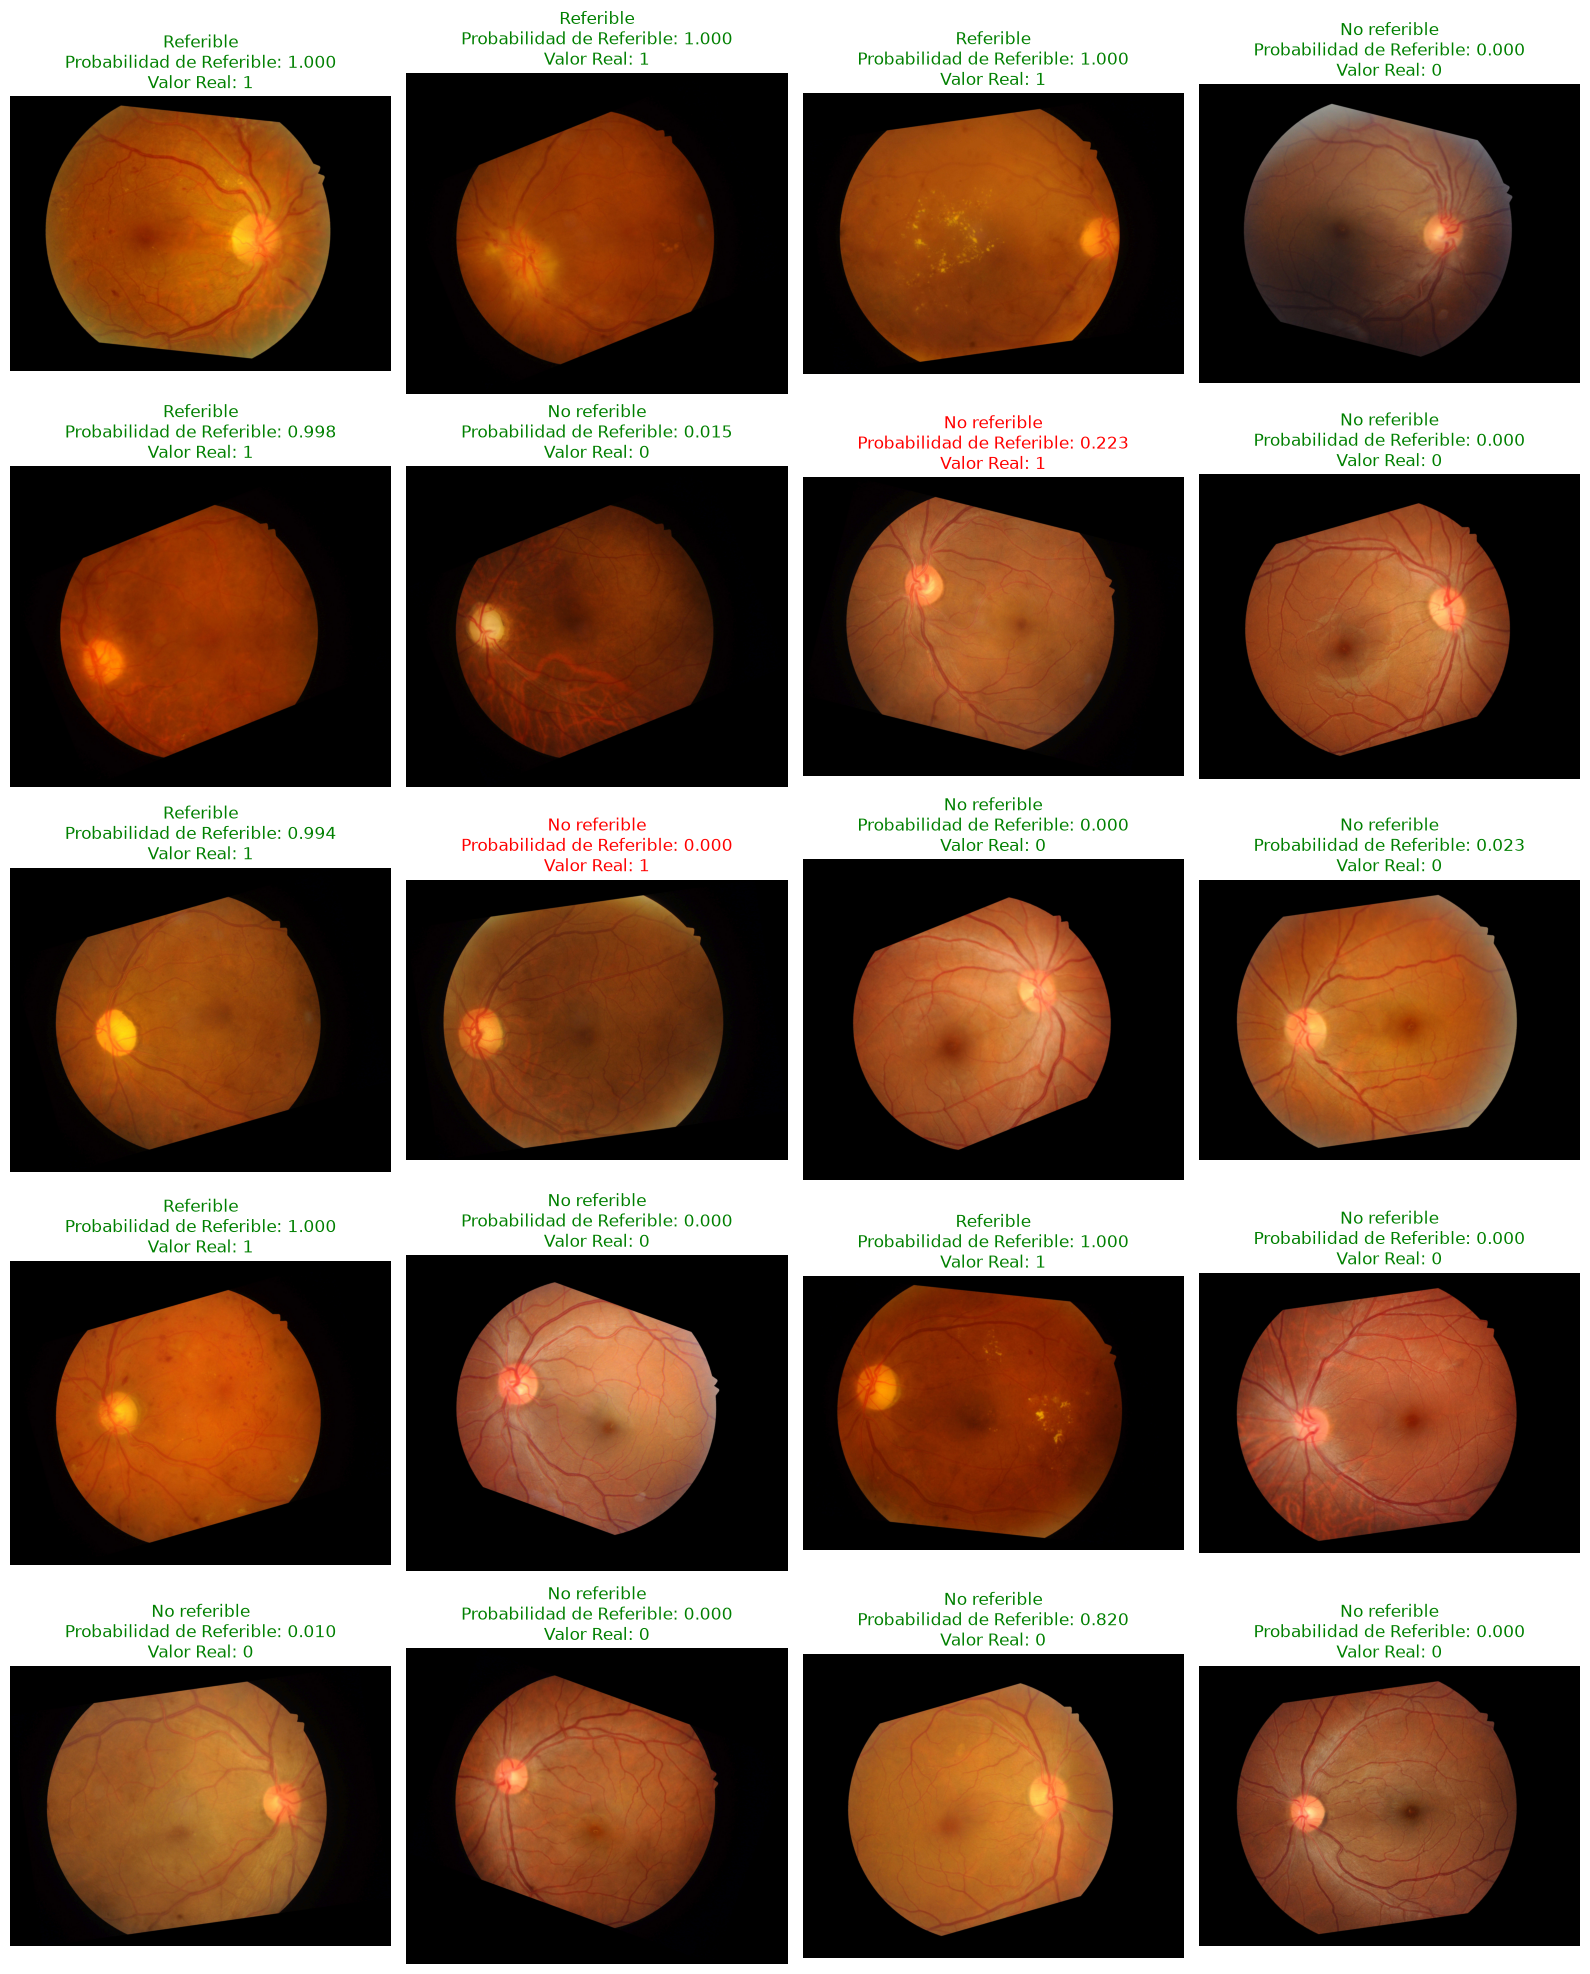

In [ ]:

if not external_predictions_df.empty:
    number_to_show = min(
        20,
        len(external_predictions_df),
    )

    selected_rows = (
        external_predictions_df
        .head(number_to_show)
    )

    columns = 4
    rows = math.ceil(
        number_to_show / columns
    )

    plt.figure(
        figsize=(16, rows * 4)
    )

    for plot_index, (_, row) in enumerate(
        selected_rows.iterrows(),
        start=1,
    ):
        image = keras.utils.load_img(
            row["image_path"]
        )

        plt.subplot(
            rows,
            columns,
            plot_index,
        )

        plt.imshow(image)

        # Determinar si la predicción es correcta para el color
        es_correcto = int(row['predicted_label']) == int(row['Valor Verdadero'])
        color_titulo = "green" if es_correcto else "red"

        plt.title(
            f"{row['predicted_class']}\n"
            f"Probabilidad de Referible: "
            f"{row['probability_referable']:.3f}\n"
            f"Valor Real: {row['Valor Verdadero']}",
            color=color_titulo
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


#  GRAD-CAM


In [ ]:
CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)


def load_gradcam_image(image_path):
    image_bytes = tf.io.read_file(
        str(image_path)
    )

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        IMG_HEIGHT,
        IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0,
    )

    return tf.cast(image, tf.float32)


def generate_gradcam(
    image_path,
    model,
    threshold,
    backbone_name="efficientnetb0",
    last_conv_layer_name="top_activation", # Mejorado: usa la activacion tras el BN
):
    image = load_gradcam_image(
        image_path
    )

    image_batch = tf.expand_dims(
        image,
        axis=0,
    )

    backbone_model = model.get_layer(
        backbone_name
    )

    grad_backbone = keras.Model(
        inputs=backbone_model.input,
        outputs=[
            backbone_model.get_layer(
                last_conv_layer_name
            ).output,
            backbone_model.output,
        ],
    )

    gap_layer = model.get_layer("gap")
    dropout_layer = model.get_layer(
        "head_dropout"
    )

    # Get intermediate layers added to the head
    # Using the correct layer names as seen in the model summary
    dense_layer_0 = model.get_layer("dense_18")
    dropout_layer_1 = model.get_layer("dropout_18")
    dense_layer_1 = model.get_layer("dense_19")
    dropout_layer_2 = model.get_layer("dropout_19")
    dense_layer_2 = model.get_layer("dense_20")
    dropout_layer_3 = model.get_layer("dropout_20")

    prediction_layer = model.get_layer(
        "prediction"
    )

    with tf.GradientTape() as tape:
        conv_output, final_features = grad_backbone(
            image_batch,
            training=False,
        )

        x = gap_layer(final_features)
        x = dropout_layer(
            x,
            training=False,
        )

        # Apply intermediate layers
        x = dense_layer_0(x)
        x = dropout_layer_1(x, training=False)
        x = dense_layer_1(x)
        x = dropout_layer_2(x, training=False)
        x = dense_layer_2(x)
        x = dropout_layer_3(x, training=False)

        probability = prediction_layer(x)

        predicted_class = int(
            probability[0, 0].numpy()
            >= threshold
        )

        if predicted_class == 1:
            target_score = probability[:, 0]
        else:
            target_score = 1.0 - probability[:, 0]

    gradients = tape.gradient(
        target_score,
        conv_output,
    )

    channel_weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2),
    )

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output
        * channel_weights,
        axis=-1,
    )

    heatmap = tf.maximum(
        heatmap,
        0,
    )

    # Evitar divisiones por cero
    heatmap_max = tf.reduce_max(heatmap)
    if heatmap_max != 0:
        heatmap = heatmap / heatmap_max

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE,
    )[..., 0]

    heatmap = heatmap.numpy()

    image_array = image.numpy().astype(
        np.uint8
    )

    color_map = plt.get_cmap("jet")

    colored_heatmap = (
        color_map(heatmap)[..., :3] * 255
    ).astype(np.uint8)

    alpha = 0.50 # Aumentado ligeramente para mayor contraste

    overlay = np.clip(
        image_array * (1 - alpha)
        + colored_heatmap * alpha,
        0,
        255,
    ).astype(np.uint8)

    probability_value = float(
        probability[0, 0].numpy()
    )

    return {
        "image": image_array,
        "heatmap": heatmap,
        "overlay": overlay,
        "probability": probability_value,
        "predicted_class": predicted_class,
        "predicted_name": CLASS_NAMES[
            predicted_class
        ],
    }


if prediction_paths:
    gradcam_example_path = prediction_paths[0]
else:
    gradcam_example_path = Path(
        val_df.iloc[0]["image_path"]
    )

gradcam_result = generate_gradcam(
    image_path=gradcam_example_path,
    model=loaded_model,
    threshold=LOADED_THRESHOLD,
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 6),
)

axes[0].imshow(
    gradcam_result["image"]
)

axes[0].set_title("Imagen procesada")
axes[0].axis("off")

axes[1].imshow(
    gradcam_result["heatmap"],
    cmap="jet",
)

axes[1].set_title("Mapa Grad-CAM")
axes[1].axis("off")

axes[2].imshow(
    gradcam_result["overlay"]
)

axes[2].set_title(
    f"{gradcam_result['predicted_name']}\n"
    f"P(Referible): "
    f"{gradcam_result['probability']:.3f}"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

ValueError: No such layer: dense_18. Existing layers are: ['image', 'cast_to_float', 'data_augmentation', 'efficientnetb0', 'gap', 'head_dropout', 'dense', 'dropout', 'dense_1', 'dropout_1', 'dense_2', 'dropout_2', 'prediction'].


ARQUITECTURA DEL MODELO CARGADO
  0 | image                          | InputLayer
  1 | cast_to_float                  | Rescaling
  2 | data_augmentation              | Sequential
  3 | efficientnetb0                 | Functional
  4 | gap                            | GlobalAveragePooling2D
  5 | head_dropout                   | Dropout
  6 | dense                          | Dense
  7 | dropout                        | Dropout
  8 | dense_1                        | Dense
  9 | dropout_1                      | Dropout
 10 | dense_2                        | Dense
 11 | dropout_2                      | Dropout
 12 | prediction                     | Dense

ÚLTIMAS 20 CAPAS DE EfficientNetB0
  0 | block6d_project_conv                     | Conv2D
  1 | block6d_project_bn                       | BatchNormalization
  2 | block6d_drop                             | Dropout
  3 | block6d_add                              | Add
  4 | block7a_expand_conv                      | Conv2D
  5 | block7

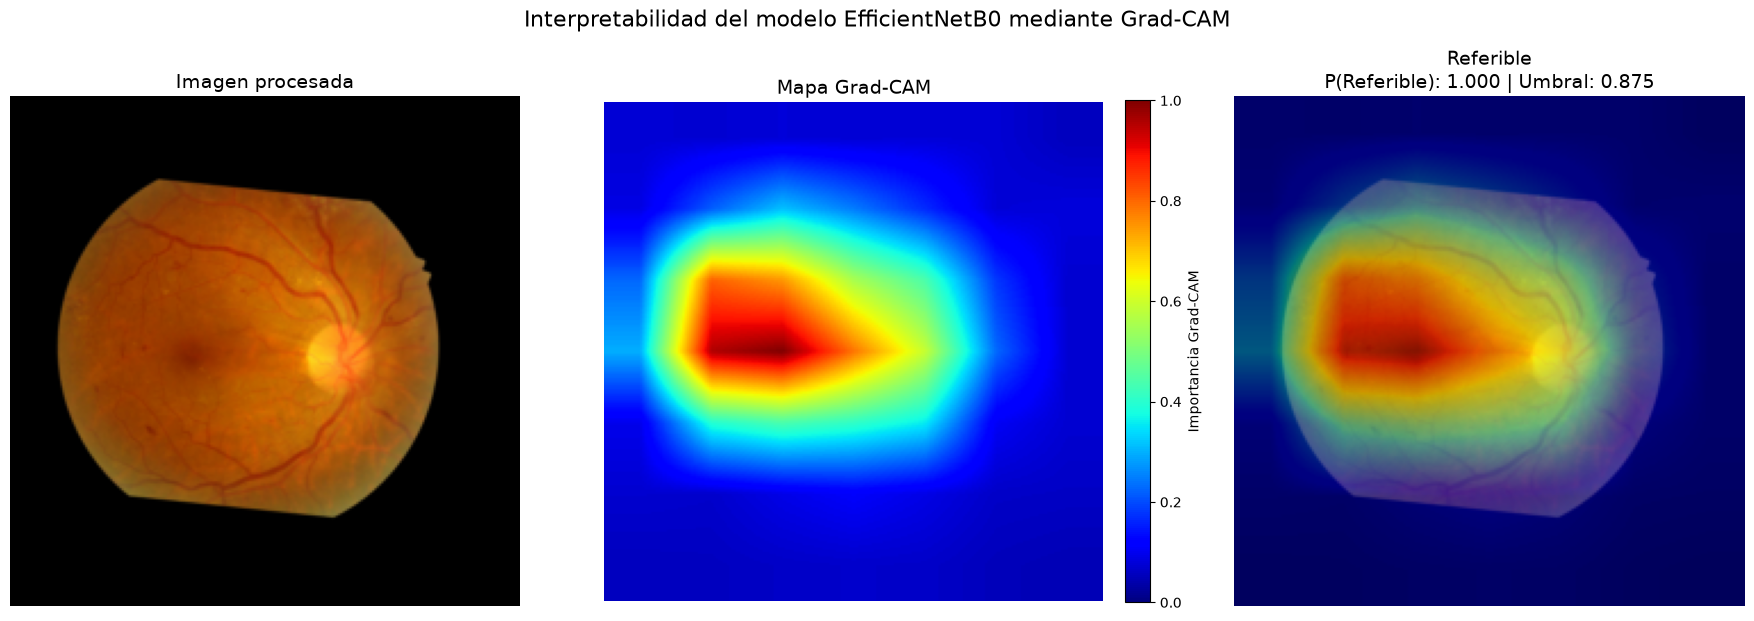

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)


# ============================================================
# CARGAR Y PREPROCESAR IMAGEN PARA GRAD-CAM
# ============================================================

def load_gradcam_image(image_path):

    image_bytes = tf.io.read_file(
        str(image_path)
    )

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    # Fijar número de canales
    image.set_shape([
        None,
        None,
        3
    ])

    # Redimensionar conservando proporción
    image = tf.image.resize_with_pad(
        image,
        IMG_HEIGHT,
        IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    # Limitar valores válidos
    image = tf.clip_by_value(
        image,
        0.0,
        255.0,
    )

    # EfficientNet de Keras puede recibir
    # directamente valores de imagen en este rango
    return tf.cast(
        image,
        tf.float32
    )


# ============================================================
# FUNCIÓN PRINCIPAL GRAD-CAM
# ============================================================

def generate_gradcam(
    image_path,
    model,
    threshold,
    backbone_name="efficientnetb0",
    last_conv_layer_name="top_activation",
):

    # ========================================================
    # 1. CARGAR IMAGEN
    # ========================================================

    image = load_gradcam_image(
        image_path
    )

    image_batch = tf.expand_dims(
        image,
        axis=0
    )


    # ========================================================
    # 2. OBTENER EfficientNetB0
    # ========================================================

    try:

        backbone_model = model.get_layer(
            backbone_name
        )

    except ValueError:

        raise ValueError(
            f"\nNo se encontró una capa llamada "
            f"'{backbone_name}' dentro del modelo.\n"
            f"Revisa model.summary()."
        )


    # ========================================================
    # 3. COMPROBAR QUE top_activation EXISTE
    # ========================================================

    backbone_layer_names = [
        layer.name
        for layer in backbone_model.layers
    ]

    if last_conv_layer_name not in backbone_layer_names:

        raise ValueError(
            f"\nLa capa '{last_conv_layer_name}' "
            f"no existe dentro de '{backbone_name}'.\n"
            f"Revisa las últimas capas de EfficientNetB0."
        )


    # ========================================================
    # 4. MODELO INTERMEDIO PARA GRAD-CAM
    # ========================================================

    grad_backbone = keras.Model(
        inputs=backbone_model.input,
        outputs=[
            backbone_model.get_layer(
                last_conv_layer_name
            ).output,
            backbone_model.output,
        ],
        name="gradcam_backbone",
    )


    # ========================================================
    # 5. IDENTIFICAR AUTOMÁTICAMENTE LA CABEZA DEL MODELO
    # ========================================================

    backbone_index = None

    for i, layer in enumerate(model.layers):

        if layer.name == backbone_name:

            backbone_index = i
            break


    if backbone_index is None:

        raise ValueError(
            f"No se pudo localizar "
            f"'{backbone_name}' "
            f"dentro del modelo."
        )


    # Todas las capas posteriores al backbone
    head_layers = model.layers[
        backbone_index + 1:
    ]


    if len(head_layers) == 0:

        raise ValueError(
            "No existen capas posteriores "
            "al backbone."
        )


    print("\n" + "=" * 70)

    print(
        "CAPAS DE LA CABEZA UTILIZADAS POR GRAD-CAM"
    )

    print("=" * 70)


    for i, layer in enumerate(
        head_layers
    ):

        print(
            f"{i:2d} | "
            f"{layer.name:30s} | "
            f"{layer.__class__.__name__}"
        )


    print("=" * 70)


    # ========================================================
    # 6. GRADIENT TAPE
    # ========================================================

    with tf.GradientTape() as tape:

        # ----------------------------------------------------
        # Pasar imagen por EfficientNetB0
        # ----------------------------------------------------

        conv_output, x = grad_backbone(
            image_batch,
            training=False,
        )


        # ----------------------------------------------------
        # Ejecutar TODA la cabeza automáticamente
        # ----------------------------------------------------

        for layer in head_layers:

            try:

                x = layer(
                    x,
                    training=False
                )

            except TypeError:

                x = layer(x)


        # ----------------------------------------------------
        # SALIDA FINAL
        # ----------------------------------------------------

        probability = tf.reshape(
            x,
            [-1]
        )


        if tf.size(probability) != 1:

            raise ValueError(
                "\nSe esperaba una salida binaria "
                "con una sola neurona sigmoid.\n"
                f"Forma obtenida: {x.shape}"
            )


        probability_referible = (
            probability[0]
        )


        # ----------------------------------------------------
        # CLASIFICACIÓN SEGÚN UMBRAL
        # ----------------------------------------------------

        predicted_class_tensor = tf.cast(
            probability_referible
            >= threshold,
            tf.int32
        )


        # ----------------------------------------------------
        # SCORE A EXPLICAR
        # ----------------------------------------------------
        #
        # Si predice REFERIBLE:
        # usamos directamente P(referible)
        #
        # Si predice NO REFERIBLE:
        # usamos 1 - P(referible)
        #
        # ----------------------------------------------------

        target_score = tf.where(
            predicted_class_tensor == 1,
            probability_referible,
            1.0 - probability_referible,
        )


    # ========================================================
    # 7. OBTENER GRADIENTES
    # ========================================================

    gradients = tape.gradient(
        target_score,
        conv_output
    )


    if gradients is None:

        raise RuntimeError(
            "\nNo se pudieron calcular los gradientes.\n"
            "La capa seleccionada puede no estar "
            "correctamente conectada con la salida."
        )


    # ========================================================
    # 8. PROMEDIO GLOBAL DE LOS GRADIENTES
    # ========================================================

    channel_weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )


    # Eliminar dimensión batch
    conv_output = conv_output[0]


    # ========================================================
    # 9. CONSTRUIR MAPA Grad-CAM
    # ========================================================

    heatmap = tf.reduce_sum(
        conv_output
        * channel_weights,
        axis=-1
    )


    # ========================================================
    # 10. ReLU
    # ========================================================

    heatmap = tf.nn.relu(
        heatmap
    )


    # ========================================================
    # 11. NORMALIZACIÓN SEGURA ENTRE 0 Y 1
    # ========================================================

    heatmap_max = tf.reduce_max(
        heatmap
    )


    heatmap = heatmap / tf.maximum(
        heatmap_max,
        tf.keras.backend.epsilon()
    )


    # ========================================================
    # 12. REDIMENSIONAR EL MAPA A 224 x 224
    # ========================================================

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE,
        method="bilinear"
    )[..., 0]


    heatmap = tf.clip_by_value(
        heatmap,
        0.0,
        1.0
    )


    heatmap = heatmap.numpy()


    # ========================================================
    # 13. CONVERTIR IMAGEN A NUMPY
    # ========================================================

    image_array = (
        image.numpy()
        .clip(0, 255)
        .astype(np.uint8)
    )


    # ========================================================
    # 14. CREAR MAPA DE COLOR
    # ========================================================

    color_map = plt.get_cmap(
        "jet"
    )


    colored_heatmap = (
        color_map(
            heatmap
        )[..., :3]
        * 255
    ).astype(
        np.uint8
    )


    # ========================================================
    # 15. CREAR SUPERPOSICIÓN
    # ========================================================

    alpha = 0.50


    overlay = np.clip(

        image_array
        * (1.0 - alpha)

        +

        colored_heatmap
        * alpha,

        0,
        255,

    ).astype(
        np.uint8
    )


    # ========================================================
    # 16. RESULTADOS NUMÉRICOS
    # ========================================================

    probability_value = float(
        probability_referible.numpy()
    )


    predicted_class = int(
        predicted_class_tensor.numpy()
    )


    predicted_name = CLASS_NAMES[
        predicted_class
    ]


    # ========================================================
    # 17. RETORNAR RESULTADO
    # ========================================================

    return {

        "image":
            image_array,

        "heatmap":
            heatmap,

        "overlay":
            overlay,

        "probability":
            probability_value,

        "predicted_class":
            predicted_class,

        "predicted_name":
            predicted_name,

    }


# ============================================================
# COMPROBACIÓN DEL MODELO CARGADO
# ============================================================

print("\n" + "=" * 80)
print("ARQUITECTURA DEL MODELO CARGADO")
print("=" * 80)


for i, layer in enumerate(
    loaded_model.layers
):

    print(
        f"{i:3d} | "
        f"{layer.name:30s} | "
        f"{layer.__class__.__name__}"
    )


print("=" * 80)


# ============================================================
# COMPROBAR EfficientNetB0
# ============================================================

backbone = loaded_model.get_layer(
    "efficientnetb0"
)


print("\n" + "=" * 80)

print(
    "ÚLTIMAS 20 CAPAS DE EfficientNetB0"
)

print("=" * 80)


for i, layer in enumerate(
    backbone.layers[-20:]
):

    print(
        f"{i:3d} | "
        f"{layer.name:40s} | "
        f"{layer.__class__.__name__}"
    )


print("=" * 80)


# ============================================================
# SELECCIONAR IMAGEN PARA Grad-CAM
# ============================================================

if (
    "prediction_paths" in globals()
    and prediction_paths
):

    gradcam_example_path = (
        prediction_paths[0]
    )

else:

    gradcam_example_path = Path(
        val_df.iloc[0]["image_path"]
    )


print(
    "\nImagen utilizada para Grad-CAM:"
)

print(
    gradcam_example_path
)


# ============================================================
# GENERAR Grad-CAM
# ============================================================

gradcam_result = generate_gradcam(

    image_path=
        gradcam_example_path,

    model=
        loaded_model,

    threshold=
        LOADED_THRESHOLD,

    backbone_name=
        "efficientnetb0",

    last_conv_layer_name=
        "top_activation",
)


# ============================================================
# MOSTRAR RESULTADO NUMÉRICO
# ============================================================

print("\n" + "=" * 70)

print(
    "RESULTADO DE LA PREDICCIÓN"
)

print("=" * 70)


print(
    f"Clase predicha: "
    f"{gradcam_result['predicted_name']}"
)


print(
    f"P(Referible): "
    f"{gradcam_result['probability']:.6f}"
)


print(
    f"Umbral utilizado: "
    f"{LOADED_THRESHOLD:.6f}"
)


print("=" * 70)


# ============================================================
# VISUALIZACIÓN
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)


# ============================================================
# PANEL 1: IMAGEN ORIGINAL PROCESADA
# ============================================================

axes[0].imshow(
    gradcam_result[
        "image"
    ]
)

axes[0].set_title(
    "Imagen procesada",
    fontsize=14
)

axes[0].axis(
    "off"
)


# ============================================================
# PANEL 2: MAPA Grad-CAM
# ============================================================

heatmap_plot = axes[1].imshow(

    gradcam_result[
        "heatmap"
    ],

    cmap="jet",

    vmin=0,
    vmax=1,
)


axes[1].set_title(
    "Mapa Grad-CAM",
    fontsize=14
)

axes[1].axis(
    "off"
)


# ============================================================
# PANEL 3: SUPERPOSICIÓN
# ============================================================

axes[2].imshow(
    gradcam_result[
        "overlay"
    ]
)


axes[2].set_title(

    f"{gradcam_result['predicted_name']}\n"

    f"P(Referible): "
    f"{gradcam_result['probability']:.3f} | "

    f"Umbral: "
    f"{LOADED_THRESHOLD:.3f}",

    fontsize=14,
)


axes[2].axis(
    "off"
)


# ============================================================
# BARRA DE COLOR
# ============================================================

fig.colorbar(

    heatmap_plot,

    ax=axes[1],

    fraction=0.046,

    pad=0.04,

    label="Importancia Grad-CAM"
)


# ============================================================
# TÍTULO GENERAL
# ============================================================

fig.suptitle(

    "Interpretabilidad del modelo EfficientNetB0 mediante Grad-CAM",

    fontsize=16,

    y=1.02
)


plt.tight_layout()

plt.show()


# DASHBOARD


In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

dashboard = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[
        "Pérdida",
        "ROC AUC",
        "PR AUC",
        "Matriz de confusión",
        "Curva ROC",
        "Métricas principales",
    ],
)

# Pérdida
dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["loss"],
        mode="lines",
        name="Loss entrenamiento",
    ),
    row=1,
    col=1,
)

dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["val_loss"],
        mode="lines",
        name="Loss validación",
    ),
    row=1,
    col=1,
)

# ROC AUC
dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["auc_roc"],
        mode="lines",
        name="ROC AUC entrenamiento",
    ),
    row=1,
    col=2,
)

dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["val_auc_roc"],
        mode="lines",
        name="ROC AUC validación",
    ),
    row=1,
    col=2,
)

# PR AUC
dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["auc_pr"],
        mode="lines",
        name="PR AUC entrenamiento",
    ),
    row=1,
    col=3,
)

dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["val_auc_pr"],
        mode="lines",
        name="PR AUC validación",
    ),
    row=1,
    col=3,
)

# Matriz de confusión
dashboard.add_trace(
    go.Heatmap(
        z=cm_selected,
        x=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        y=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        text=cm_selected,
        texttemplate="%{text}",
        showscale=False,
        name="Confusión",
    ),
    row=2,
    col=1,
)

# Curva ROC
dashboard.add_trace(
    go.Scatter(
        x=fpr_curve,
        y=tpr_curve,
        mode="lines",
        name="ROC",
    ),
    row=2,
    col=2,
)

dashboard.add_trace(
    go.Scatter(
        x=[0, 1],
        y=[0, 1],
        mode="lines",
        line=dict(dash="dash"),
        name="Clasificador aleatorio",
    ),
    row=2,
    col=2,
)

# Barras de métricas
metric_names = [
    "Accuracy",
    "Precisión",
    "Sensibilidad",
    "Especificidad",
    "F1",
]

metric_values = [
    metrics_selected["accuracy"],
    metrics_selected["precision"],
    metrics_selected["sensitivity_recall"],
    metrics_selected["specificity"],
    metrics_selected["f1_score"],
]

dashboard.add_trace(
    go.Bar(
        x=metric_names,
        y=metric_values,
        text=[
            f"{value:.3f}"
            for value in metric_values
        ],
        textposition="auto",
        name="Métricas",
    ),
    row=2,
    col=3,
)

dashboard.update_yaxes(
    range=[0, 1],
    row=2,
    col=3,
)

dashboard.update_layout(
    title=(
        "Dashboard EfficientNetB0 — "
        "Retinopatía diabética referible"
    ),
    height=850,
    width=1500,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.18,
        xanchor="center",
        x=0.5,
    ),
)

dashboard.show()

dashboard.write_html(
    str(DASHBOARD_PATH)
)

print(
    "Dashboard guardado en:",
    DASHBOARD_PATH,
)

Dashboard guardado en: c:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\dashboard_efficientnetb0.html


In [ ]:
import sys

print("Python usado por este notebook:")
print(sys.executable)

Python usado por este notebook:
c:\r50torch\Scripts\python.exe


In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "plotly"
])

print("Plotly instalado correctamente")

Plotly instalado correctamente


In [ ]:
# ============================================================
# DASHBOARD FINAL - EfficientNetB0
# Clasificación binaria de retinopatía diabética referible
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}


# ============================================================
# 2. DEFINIR RUTA DE SALIDA SI TODAVÍA NO EXISTE
# ============================================================

if "DASHBOARD_PATH" not in globals():

    DASHBOARD_PATH = Path(
        "dashboard_efficientnetb0_retinopatia.html"
    )

else:

    DASHBOARD_PATH = Path(
        DASHBOARD_PATH
    )


# Crear carpeta de salida si fuera necesario
DASHBOARD_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 3. VALIDACIONES GENERALES
# ============================================================

required_variables = [
    "history_df",
    "cm_selected",
    "fpr_curve",
    "tpr_curve",
    "metrics_selected",
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]


if missing_variables:

    raise NameError(
        "\nFaltan variables necesarias para crear "
        "el dashboard:\n\n"
        + "\n".join(
            f"  - {variable}"
            for variable in missing_variables
        )
    )


# ============================================================
# 4. VALIDAR history_df
# ============================================================

if not isinstance(
    history_df,
    pd.DataFrame
):

    history_df = pd.DataFrame(
        history_df
    )


if history_df.empty:

    raise ValueError(
        "history_df está vacío."
    )


print("=" * 80)
print("COLUMNAS DISPONIBLES EN history_df")
print("=" * 80)

for column in history_df.columns:

    print(
        f" - {column}"
    )

print("=" * 80)


# ============================================================
# 5. FUNCIÓN PARA LOCALIZAR COLUMNAS
# ============================================================

def find_history_column(
    dataframe,
    candidates,
    required=True,
):

    """
    Busca la primera columna disponible entre
    varios posibles nombres.
    """

    for candidate in candidates:

        if candidate in dataframe.columns:

            return candidate

    if required:

        raise KeyError(
            "\nNo se encontró ninguna de estas "
            "columnas en history_df:\n"
            f"{candidates}\n\n"
            "Columnas existentes:\n"
            f"{list(dataframe.columns)}"
        )

    return None


# ============================================================
# 6. IDENTIFICAR COLUMNAS DEL HISTORIAL
# ============================================================

# Epoch
epoch_col = find_history_column(
    history_df,
    [
        "epoch",
        "epochs",
    ],
    required=False,
)


# Si no existe columna epoch, crearla
if epoch_col is None:

    history_df = history_df.copy()

    history_df[
        "epoch"
    ] = np.arange(
        1,
        len(history_df) + 1
    )

    epoch_col = "epoch"


# Loss
loss_col = find_history_column(
    history_df,
    [
        "loss",
    ],
)


val_loss_col = find_history_column(
    history_df,
    [
        "val_loss",
    ],
)


# ROC AUC entrenamiento
roc_auc_col = find_history_column(
    history_df,
    [
        "auc_roc",
        "roc_auc",
        "auc",
        "AUC",
    ],
)


# ROC AUC validación
val_roc_auc_col = find_history_column(
    history_df,
    [
        "val_auc_roc",
        "val_roc_auc",
        "val_auc",
        "val_AUC",
    ],
)


# PR AUC entrenamiento
pr_auc_col = find_history_column(
    history_df,
    [
        "auc_pr",
        "pr_auc",
        "auc_prc",
        "prc",
    ],
)


# PR AUC validación
val_pr_auc_col = find_history_column(
    history_df,
    [
        "val_auc_pr",
        "val_pr_auc",
        "val_auc_prc",
        "val_prc",
    ],
)


print("\nColumnas identificadas:")
print(f"Epoch           : {epoch_col}")
print(f"Loss            : {loss_col}")
print(f"Val Loss        : {val_loss_col}")
print(f"ROC AUC         : {roc_auc_col}")
print(f"Val ROC AUC     : {val_roc_auc_col}")
print(f"PR AUC          : {pr_auc_col}")
print(f"Val PR AUC      : {val_pr_auc_col}")


# ============================================================
# 7. VALIDAR MATRIZ DE CONFUSIÓN
# ============================================================

cm_selected = np.asarray(
    cm_selected
)


if cm_selected.shape != (2, 2):

    raise ValueError(
        "\ncm_selected debe tener forma (2, 2).\n"
        f"Forma actual: {cm_selected.shape}"
    )


# Convertir a enteros
cm_selected = cm_selected.astype(
    int
)


# ============================================================
# 8. VALIDAR CURVA ROC
# ============================================================

fpr_curve = np.asarray(
    fpr_curve,
    dtype=float,
).ravel()


tpr_curve = np.asarray(
    tpr_curve,
    dtype=float,
).ravel()


if len(fpr_curve) != len(tpr_curve):

    raise ValueError(
        "\nfpr_curve y tpr_curve deben tener "
        "la misma longitud.\n"
        f"FPR: {len(fpr_curve)}\n"
        f"TPR: {len(tpr_curve)}"
    )


# ============================================================
# 9. FUNCIÓN SEGURA PARA EXTRAER MÉTRICAS
# ============================================================

def get_metric_value(
    metrics_dict,
    possible_keys,
):

    for key in possible_keys:

        if key in metrics_dict:

            value = metrics_dict[
                key
            ]

            return float(value)

    raise KeyError(
        "\nNo se encontró ninguna de estas "
        "métricas:\n"
        f"{possible_keys}\n\n"
        "Claves disponibles:\n"
        f"{list(metrics_dict.keys())}"
    )


# ============================================================
# 10. EXTRAER MÉTRICAS PRINCIPALES
# ============================================================

accuracy_value = get_metric_value(
    metrics_selected,
    [
        "accuracy",
        "Accuracy",
    ],
)


precision_value = get_metric_value(
    metrics_selected,
    [
        "precision",
        "Precision",
    ],
)


sensitivity_value = get_metric_value(
    metrics_selected,
    [
        "sensitivity_recall",
        "sensitivity",
        "recall",
        "Recall",
    ],
)


specificity_value = get_metric_value(
    metrics_selected,
    [
        "specificity",
        "Specificity",
    ],
)


f1_value = get_metric_value(
    metrics_selected,
    [
        "f1_score",
        "f1",
        "F1",
    ],
)


metric_names = [
    "Accuracy",
    "Precisión",
    "Sensibilidad",
    "Especificidad",
    "F1",
]


metric_values = [
    accuracy_value,
    precision_value,
    sensitivity_value,
    specificity_value,
    f1_value,
]


# ============================================================
# 11. CREAR DASHBOARD
# ============================================================

dashboard = make_subplots(

    rows=2,
    cols=3,

    subplot_titles=[
        "Pérdida",
        "ROC AUC",
        "PR AUC",
        "Matriz de confusión",
        "Curva ROC",
        "Métricas principales",
    ],

    horizontal_spacing=0.08,
    vertical_spacing=0.15,
)


# ============================================================
# 12. PÉRDIDA
# ============================================================

dashboard.add_trace(

    go.Scatter(

        x=history_df[
            epoch_col
        ],

        y=history_df[
            loss_col
        ],

        mode="lines",

        name="Loss entrenamiento",

    ),

    row=1,
    col=1,
)


dashboard.add_trace(

    go.Scatter(

        x=history_df[
            epoch_col
        ],

        y=history_df[
            val_loss_col
        ],

        mode="lines",

        name="Loss validación",

    ),

    row=1,
    col=1,
)


# ============================================================
# 13. ROC AUC
# ============================================================

dashboard.add_trace(

    go.Scatter(

        x=history_df[
            epoch_col
        ],

        y=history_df[
            roc_auc_col
        ],

        mode="lines",

        name="ROC AUC entrenamiento",

    ),

    row=1,
    col=2,
)


dashboard.add_trace(

    go.Scatter(

        x=history_df[
            epoch_col
        ],

        y=history_df[
            val_roc_auc_col
        ],

        mode="lines",

        name="ROC AUC validación",

    ),

    row=1,
    col=2,
)


# ============================================================
# 14. PR AUC
# ============================================================

dashboard.add_trace(

    go.Scatter(

        x=history_df[
            epoch_col
        ],

        y=history_df[
            pr_auc_col
        ],

        mode="lines",

        name="PR AUC entrenamiento",

    ),

    row=1,
    col=3,
)


dashboard.add_trace(

    go.Scatter(

        x=history_df[
            epoch_col
        ],

        y=history_df[
            val_pr_auc_col
        ],

        mode="lines",

        name="PR AUC validación",

    ),

    row=1,
    col=3,
)


# ============================================================
# 15. MATRIZ DE CONFUSIÓN
# ============================================================

dashboard.add_trace(

    go.Heatmap(

        z=cm_selected,

        x=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],

        y=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],

        text=cm_selected,

        texttemplate="%{text}",

        showscale=False,

        hovertemplate=(
            "Real: %{y}<br>"
            "Predicción: %{x}<br>"
            "N: %{z}"
            "<extra></extra>"
        ),

        name="Matriz de confusión",

    ),

    row=2,
    col=1,
)


# ============================================================
# 16. CURVA ROC
# ============================================================

dashboard.add_trace(

    go.Scatter(

        x=fpr_curve,

        y=tpr_curve,

        mode="lines",

        name="Curva ROC",

    ),

    row=2,
    col=2,
)


# Línea de referencia aleatoria
dashboard.add_trace(

    go.Scatter(

        x=[0, 1],

        y=[0, 1],

        mode="lines",

        line=dict(
            dash="dash"
        ),

        name="Clasificador aleatorio",

    ),

    row=2,
    col=2,
)


# ============================================================
# 17. MÉTRICAS PRINCIPALES
# ============================================================

dashboard.add_trace(

    go.Bar(

        x=metric_names,

        y=metric_values,

        text=[
            f"{value:.3f}"
            for value in metric_values
        ],

        textposition="auto",

        name="Métricas",

        hovertemplate=(
            "%{x}: %{y:.4f}"
            "<extra></extra>"
        ),

    ),

    row=2,
    col=3,
)


# ============================================================
# 18. CONFIGURAR EJES
# ============================================================

# Pérdida
dashboard.update_xaxes(
    title_text="Época",
    row=1,
    col=1,
)

dashboard.update_yaxes(
    title_text="Loss",
    row=1,
    col=1,
)


# ROC AUC entrenamiento
dashboard.update_xaxes(
    title_text="Época",
    row=1,
    col=2,
)

dashboard.update_yaxes(
    title_text="ROC AUC",
    range=[0, 1],
    row=1,
    col=2,
)


# PR AUC entrenamiento
dashboard.update_xaxes(
    title_text="Época",
    row=1,
    col=3,
)

dashboard.update_yaxes(
    title_text="PR AUC",
    range=[0, 1],
    row=1,
    col=3,
)


# Matriz de confusión
dashboard.update_xaxes(
    title_text="Clase predicha",
    row=2,
    col=1,
)

dashboard.update_yaxes(
    title_text="Clase real",
    autorange="reversed",
    row=2,
    col=1,
)


# Curva ROC
dashboard.update_xaxes(
    title_text="Tasa de falsos positivos (FPR)",
    range=[0, 1],
    row=2,
    col=2,
)

dashboard.update_yaxes(
    title_text="Sensibilidad (TPR)",
    range=[0, 1],
    row=2,
    col=2,
)


# Métricas
dashboard.update_yaxes(
    title_text="Valor",
    range=[0, 1],
    row=2,
    col=3,
)


# ============================================================
# 19. CONFIGURACIÓN GENERAL DEL DASHBOARD
# ============================================================

dashboard.update_layout(

    title=dict(

        text=(
            "Dashboard EfficientNetB0 — "
            "Clasificación de retinopatía diabética referible"
        ),

        x=0.5,

        xanchor="center",
    ),

    height=900,

    width=1500,

    template="plotly_white",

    legend=dict(

        orientation="h",

        yanchor="top",

        y=-0.12,

        xanchor="center",

        x=0.5,
    ),

    margin=dict(
        l=70,
        r=50,
        t=100,
        b=140,
    ),
)


# ============================================================
# 20. MOSTRAR DASHBOARD
# ============================================================

dashboard.show()


# ============================================================
# 21. GUARDAR EN HTML
# ============================================================

dashboard.write_html(

    str(
        DASHBOARD_PATH
    ),

    include_plotlyjs=True,

    full_html=True,
)


print("\n" + "=" * 80)

print(
    "DASHBOARD GENERADO CORRECTAMENTE"
)

print("=" * 80)

print(
    "Archivo guardado en:"
)

print(
    DASHBOARD_PATH.resolve()
)

print("=" * 80)

COLUMNAS DISPONIBLES EN history_df
 - epoch
 - accuracy
 - auc_pr
 - auc_roc
 - loss
 - precision
 - recall
 - val_accuracy
 - val_auc_pr
 - val_auc_roc
 - val_loss
 - val_precision
 - val_recall
 - learning_rate
 - phase

Columnas identificadas:
Epoch           : epoch
Loss            : loss
Val Loss        : val_loss
ROC AUC         : auc_roc
Val ROC AUC     : val_auc_roc
PR AUC          : auc_pr
Val PR AUC      : val_auc_pr



DASHBOARD GENERADO CORRECTAMENTE
Archivo guardado en:
C:\Users\lauri\Documents\PROYECTO FINAL\efficientnetb0_rdr\dashboard_efficientnetb0.html
